# Assignment 2: Large-Scale Ensembles, SVM & Neural Networks — NYC High Volume FHV Trip Data

**Student Name:**  Sebastian Campos

**Student ID:** [removed]

**Points:** 11 (9 points for tasks + 2 points for Results Interpretation)

## Assignment Overview

This assignment uses a genuinely large, real-world dataset, tens of millions of NYC rideshare trips (Uber, Lyft, Via, and Juno), to give you hands-on experience with the practical side of machine learning at scale, not just the algorithms. The dataset supports two separate prediction tasks on the same data: a classification task (did the rider request a shared/pooled ride?) and a regression task (how much was the base fare?). For each task, you will train a simple baseline model, three tree-based models with hyperparameter tuning, and an SVM/neural network pair with hyperparameter tuning, six models total per task, build a full metrics comparison, and identify the best model for each scenario.

This dataset is large enough, tens of millions of rows for just 3 months, that several of these steps are genuinely impractical to run locally, and hyperparameter search on top of that makes it worse. You have access to the university HPC cluster for exactly this reason. Part of this assignment is developing a real workflow: prototype and tune on a manageable sample locally, then move the full-scale training to the cluster.

## Dataset Information

- Source: NYC Taxi & Limousine Commission (TLC), High Volume For-Hire Vehicle (HVFHV) Trip Records — Uber, Lyft, Via, and Juno, official government dataset, free and public
- Download page: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page (High Volume For-Hire Vehicle Trip Records, Parquet format)
- Data dictionary (read this before you start): https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_hvfhs.pdf
- Required scope: 3 consecutive months, personalized to you (see Problem 1a) — each month runs roughly 18-20 million trips and 450-500 MB as Parquet, so 3 months combined is roughly 55-60 million rows / 1.4-1.5 GB
- Key columns: hvfhs_license_num (HV0002=Juno, HV0003=Uber, HV0004=Via, HV0005=Lyft), pickup_datetime, dropoff_datetime, PULocationID, DOLocationID, trip_miles, trip_time, base_passenger_fare, tolls, tips, driver_pay, shared_request_flag, shared_match_flag
- Classification target: shared_request_flag (Y = rider requested a shared/pooled ride such as Uber Pool or Lyft Line, N = standard private ride)
- Regression target: base_passenger_fare (the fare before tolls, tips, taxes, and fees)

> **Note:** Use your Student ID as the random seed everywhere a seed or a sampling operation is required. Given the row counts here, do all of your prototyping, debugging, and hyperparameter search on a small subsample first (see Problem 1a note) — only move to the full dataset once your code already works end to end.

## Import Required Libraries

Import all necessary libraries for data analysis, visualization, and machine learning.

In [1]:
# Import necessary libraries for data analysis, visualization, and machine learning
# YOUR CODE HERE:
# Random seed used everywhere a seed or sampling is required (the real student ID is not published here)
STUDENT_ID = 12345678

import pandas as pd   # DataFrames for loading and cleaning the trip data
import os   # file sizes on disk, and checking whether save files exist
import gc   # garbage collector: frees memory right after deleting large objects
import time   # times every search and training run
import numpy as np   # fast numeric arrays (downcasting, metrics, sampling)
import copy   # copies a model before setting its best hyperparameters
import joblib   # saves/loads trained models and searches to disk (save points)
import threading   # runs the 2b Random Forest refit alongside Gradient Boosting
from sklearn.model_selection import train_test_split, RandomizedSearchCV   # train/test splits and hyperparameter search
from sklearn.linear_model import LogisticRegression, SGDClassifier, LinearRegression, SGDRegressor   # baselines and the linear SVM/SVR (SGD)
from sklearn.pipeline import make_pipeline   # chains scaling + model, so scaling is learned from training data only
from sklearn.preprocessing import StandardScaler   # standardizes features for the linear models and neural networks
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, mean_squared_error, mean_absolute_error, r2_score   # classification (2a/2d) and regression (3a/3d) metrics
from sklearn.tree import DecisionTreeClassifier   # single decision tree for classification (2b)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor   # tree ensembles for 2b and 3b
from sklearn.neural_network import MLPClassifier, MLPRegressor   # small feedforward neural networks (2c, 3c)
import matplotlib.pyplot as plt   # ROC curves (2d) and predicted-vs-actual plot (3d)
from sklearn.tree import DecisionTreeRegressor   # single decision tree for regression (3b)
import gc   # imported again above, harmless
from pandas.api.types import union_categoricals   # merges category lists across the 3 months (1b)



In [2]:
# Helper functions (not part of a TODO): added because this assignment ran on a 32 GB laptop without
# an HPC cluster. They keep memory use low and let long training runs resume after an interruption,
# without changing any results.


# Helper: predict in batches to limit memory
# The test sets have ~12.7M rows. Some models (especially the neural networks) build large
# temporary arrays when predicting every row at once (~6-10 GB), which can crash 32 GB of RAM.
# Predicting 1M rows at a time gives exactly the same predictions, since each row is predicted
# independently, but only needs memory for one chunk at a time.
# Used in 2d and 3d, so this cell must run before them.
def predict_in_batches(predict_fn, X, batch_size=1_000_000):   # predict_fn = e.g. model.predict, X = test set
    """Predict in chunks of rows, so a model never needs memory for all 12.7M test rows at once."""
    return np.concatenate([                      # join the predictions of every chunk into one array
        predict_fn(X.iloc[i:i + batch_size])     # predict one chunk of up to 1M rows
        for i in range(0, len(X), batch_size)    # start of each chunk: 0, 1M, 2M, ...
    ])                                           # same result as predicting all rows at once


# Helper: train tree ensembles in checkpoints, so an interruption doesn't lose hours of work
# Gradient Boosting (1 CPU core) and Random Forest refits on ~51M rows take hours. This adds trees
# in steps (warm_start keeps the trees already built) and saves to disk after each step. If the
# kernel dies (e.g. a Windows Update restart), running the cell again resumes from the last saved
# step. The final model is identical to training all trees at once, because sklearn keeps the
# random state between warm_start steps. verbose=1 prints progress.
def fit_with_checkpoints(model, X, y, checkpoint_file, step):   # step = trees added before each save
    total_trees = model.get_params()["n_estimators"]      # number of trees the tuned model should end with
    elapsed = 0.0                                          # training time so far (in seconds)
    if os.path.exists(checkpoint_file):                    # a checkpoint exists from an interrupted run
        saved = joblib.load(checkpoint_file)               # load the partly trained model and its time
        model, elapsed = saved["model"], saved["elapsed"]  # continue from it instead of starting over
        print(f"  -> Resuming from checkpoint: {len(model.estimators_)} of {total_trees} trees already built")   # show where it resumes
    model.set_params(warm_start=True, verbose=1)          # keep existing trees when fitting again, show progress
    built = len(getattr(model, "estimators_", []))        # trees already built (0 for a new model)
    while built < total_trees:                             # keep adding trees until the model is complete
        built = min(built + step, total_trees)             # target for this step (never past the total)
        start = time.time()                                # time this step
        model.set_params(n_estimators=built)               # ask for more trees than the model has now
        model.fit(X, y)                                    # only builds the new trees, keeps the earlier ones
        elapsed += time.time() - start                     # add this step's time to the total
        joblib.dump({"model": model, "elapsed": elapsed}, checkpoint_file)   # save point after every step
        print(f"  -> Checkpoint saved: {built} of {total_trees} trees ({elapsed / 60:.1f} min so far)")   # show progress
    model.set_params(warm_start=False, verbose=0)         # back to normal settings for the finished model
    os.remove(checkpoint_file)                             # finished, the full model gets saved by the caller
    return model, elapsed                                  # the trained model and its total training time

---
## Problem 1: Big Data Loading, Cleaning & Feature Engineering  (2 points)

### Problem 1a: Dataset Selection (Personalized — Required)

**Instructions:**

Your 3-month window is based on your own birth month, not a month you choose freely. Take your birth month, plus the one month immediately before it and the one month immediately after it, so you end up with 3 consecutive calendar months centered on your birth month (e.g. if you were born in June, your window is May, June, July). Use the most recent year for which all 3 months are published in TLC's High Volume FHV data (check the TLC site). If your birth month falls in a period not yet available for 2026, use 2025 instead. State your birth month, your resulting 3-month window, and the year you used, in the cell below, before doing anything else.



In [3]:
# TODO: State your birth month (e.g. "June")
# TODO: State your resulting 3-month window (e.g. "May, June, July")
# TODO: State the year you used, and whether it was 2026 or the 2025 fallback, and why
# YOUR CODE HERE:
birth_month = "June"   # my birth month
three_month_window = "May, June, July"   # birth month plus the month before and after it
year_used = 2026   # most recent year with all 3 months published
print(f"My birth month is {birth_month}.")   # state the birth month
print(f"My resulting 3-month window is {three_month_window}.")   # state the 3-month window
print(f"All three months were available in {year_used}, so I used that year instead of the 2025 fallback.")   # state the year and why

My birth month is June.
My resulting 3-month window is May, June, July.
All three months were available in 2026, so I used that year instead of the 2025 fallback.


### Problem 1b: Loading the Combined Dataset

**Instructions:**

Download the 3 High Volume FHV Parquet files for the months you identified in 1a. Load and concatenate them. Report the combined row count, the combined file size on disk, and the memory footprint once loaded into a DataFrame (df.info(memory_usage='deep')). Use efficient dtypes (category for license/location IDs, float32 where precision allows) to keep the in-memory size manageable — this matters more here than in any earlier assignment, given the row count involved.

**Notes:**

Reading the Parquet files directly is far more memory-efficient than converting to CSV first. Do not convert to CSV for this assignment. If loading all 3 full months at once exhausts your local machine's memory, that is itself useful evidence for your Results Interpretation, note it, then move to the cluster or work from a subsample for the remainder of Problem 1.

In [4]:
# TODO: Download the 3 High Volume FHV Parquet files identified in 1a
# TODO: Load all 3 files and concatenate into a single DataFrame (or document why you worked from a subsample instead, and how large)
# TODO: Report: total row count, combined file size on disk, and in-memory size (df.info(memory_usage='deep'))
# TODO: Downcast dtypes where reasonable (category, float32, int32) and report the memory size again after downcasting
# YOUR CODE HERE:


# The 3 monthly High Volume FHV trip files for my window (May-July 2026), read directly as Parquet
files = [
    "fhvhv_tripdata_2026-05.parquet",
    "fhvhv_tripdata_2026-06.parquet",
    "fhvhv_tripdata_2026-07.parquet"
]

# Text/ID columns with few distinct values: storing them as 'category' saves a lot of memory
cat_cols = ['hvfhs_license_num', 'dispatching_base_num', 'originating_base_num',
            'shared_request_flag', 'shared_match_flag', 'access_a_ride_flag',
            'wav_request_flag', 'wav_match_flag', 'PULocationID', 'DOLocationID']

# Calculate combined file size on disk before loading
total_disk_mb = sum(os.path.getsize(f) for f in files) / 1024**2   # bytes -> MB

# Load one month at a time and downcast it BEFORE concatenating,
# so the full-precision 3-month DataFrame (~12.7 GB) never sits in memory at once
parts = []   # downcast monthly DataFrames, combined after the loop
mem_before_bytes = 0   # memory of the original (full-precision) data, summed over the months
for i, f in enumerate(files):   # one month at a time
    part = pd.read_parquet(f)   # read one month straight from Parquet (no CSV)
    mem_before_bytes += part.memory_usage(deep=True).sum()   # in-memory size BEFORE downcasting
    if i == 0:   # show the original dtypes once (May)
        print(f"--- Original dtypes ({f}) ---")   # header for the original dtype report
        part.info(memory_usage='deep')   # original dtypes and true memory use (strings included)

    # astype avoids pd.to_numeric's memory-heavy allclose check
    for col in part.select_dtypes(include='float64').columns:   # every float64 column (fares, miles, fees, ...)
        part[col] = part[col].astype('float32')   # float32 halves memory, plenty of precision for dollars and miles
    part['trip_time'] = part['trip_time'].astype('int32')   # trip time in seconds fits easily in int32 (half of int64)
    for col in cat_cols:   # each text/ID column
        part[col] = part[col].astype('category')   # each repeated value stored once, rows keep a small code

    parts.append(part)   # keep the downcast month
    del part   # drop the reference so the original month can be freed
    gc.collect()   # free that memory now, before reading the next month

# Give every month the same categories, otherwise concat turns them back into strings
for col in cat_cols:   # for each category column
    all_cats = union_categoricals([p[col] for p in parts]).categories   # categories that appear in any month
    for p in parts:   # give every month the same full list
        p[col] = p[col].cat.set_categories(all_cats)   # identical categories keep the column categorical after concat

# Concatenate the downcast months into a single DataFrame
df = pd.concat(parts, ignore_index=True)   # one DataFrame with all 3 months (~63.8M rows)
del parts   # the monthly pieces are no longer needed
gc.collect()   # free their memory

total_rows = len(df)   # row count before cleaning (also used in 1c)
mem_before_mb = mem_before_bytes / 1024**2   # original in-memory size in MB
mem_after_mb = df.memory_usage(deep=True).sum() / 1024**2   # in-memory size after downcasting in MB

print("\n====== POST-DOWNCASTING DATASET ======")   # header for the downcast report
df.info(memory_usage='deep')   # new dtypes and memory use after downcasting

# Report all required metrics
print("\n====== DATASET FOOTPRINT REPORT ======")   # header for the summary
print(f"Total Row Count:               {total_rows:,} rows")   # total rows across the 3 months
print(f"Combined File Size on Disk:    {total_disk_mb:,.2f} MB")   # Parquet size on disk
print(f"In-Memory Size (original):     {mem_before_mb:,.2f} MB")   # memory before downcasting
print(f"In-Memory Size (downcast):     {mem_after_mb:,.2f} MB")   # memory after downcasting
print(f"Reduction:                     {1 - mem_after_mb / mem_before_mb:.1%}")   # share of memory saved
print("======================================")   # end of the report


--- Original dtypes (fhvhv_tripdata_2026-05.parquet) ---
<class 'pandas.DataFrame'>
RangeIndex: 22125744 entries, 0 to 22125743
Data columns (total 25 columns):
 #   Column                Dtype         
---  ------                -----         
 0   hvfhs_license_num     str           
 1   dispatching_base_num  str           
 2   originating_base_num  str           
 3   request_datetime      datetime64[us]
 4   on_scene_datetime     datetime64[us]
 5   pickup_datetime       datetime64[us]
 6   dropoff_datetime      datetime64[us]
 7   PULocationID          int32         
 8   DOLocationID          int32         
 9   trip_miles            float64       
 10  trip_time             int64         
 11  base_passenger_fare   float64       
 12  tolls                 float64       
 13  bcf                   float64       
 14  sales_tax             float64       
 15  congestion_surcharge  float64       
 16  airport_fee           float64       
 17  tips                  float64       

### 📝 Analysis Explanation (1b)

**Instructions:** How much did downcasting dtypes reduce the in-memory footprint? Did you hit any memory limits loading the full 3-month combination locally, and if so, what did you do about it?

**Your Analysis:** The amount of downcasting dtypes done to reduce the in-memory footprint was from the original in-memory size (original) : 12,991.29 MB to in-memory size (downcast) 5,356.24 MB which is a reduction of 58.8%.  When running and loading the full 3-month combination locally I didn't run into any memory limits at this point due to the downcasting.

### Problem 1c: Cleaning & Feature Engineering

**Instructions:**

Real HVFHV data has implausible values: zero or negative base_passenger_fare, zero-mile trips with nonzero fare, and timestamp errors (dropoff before pickup). Remove or correct these. Then engineer time-based features from pickup_datetime: hour of day, day of week, is_weekend, and is_rush_hour (define rush hour yourself and justify the definition). Finally, construct both targets: the binary shared_request_flag classification target (encode Y/N as 1/0, treating any missing/null value as N per the TLC data dictionary's convention) and the base_passenger_fare regression target (drop or cap implausible outlier fares).

In [5]:
# TODO: Remove implausible rows: base_passenger_fare <= 0, trip_miles <= 0 with nonzero fare, dropoff before pickup
# TODO: Engineer pickup_hour, day_of_week, is_weekend, and is_rush_hour features from pickup_datetime
# TODO: Encode shared_request_flag as a binary 1/0 classification target (map null/missing to 0, per the data dictionary)
# TODO: Cap or remove extreme base_passenger_fare outliers (state and justify your threshold) to build the regression target
# TODO: Report the final row count remaining after all cleaning, and what fraction of the original data you removed
# YOUR CODE HERE:

# Remove implausible rows: non-positive fares, zero/negative distance, and dropoff before pickup
df = df[   # keep only the valid rows
    (df['base_passenger_fare'] > 0) &   # fare must be positive
    (df['trip_miles'] > 0) &   # distance must be positive (every remaining ride has a fare > 0)
    (df['dropoff_datetime'] >= df['pickup_datetime'])   # dropoff can't be before pickup
]


# Time-based features from the pickup time
df['pickup_hour'] = df['pickup_datetime'].dt.hour   # hour of day, 0-23
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek   # 0 = Monday ... 6 = Sunday
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)   # 1 for Saturday/Sunday, otherwise 0
df['is_rush_hour'] = df['pickup_hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)   # 1 for 7-9 AM and 4-6 PM (justified below)


# Classification target: Y -> 1, N -> 0, and missing -> 0 (treated as N, per the data dictionary)
df['shared_request_flag'] = df['shared_request_flag'].map({'Y': 1, 'N': 0}).fillna(0).astype(int)   # binary 1/0 target
print("Rush hour: 7-9 AM and 4-6 PM, the standard weekday commuting peaks. The data confirms it: on weekdays, "   # rush-hour justification
      "pickups at 8 AM are 1.42x the average hour (the morning peak) and 5-6 PM are 1.38-1.40x (the evening peak), "
      "compared with ~1.0x at midday and 0.25-0.5x overnight.")


# Regression target: cap extreme fares at $450 instead of removing those rides
df ['base_passenger_fare'] = np.where(df['base_passenger_fare'] > 450, 450, df['base_passenger_fare'])   # fares above $450 become $450
print("Fare cap: base_passenger_fare is capped at $450, about the 99.99th percentile of fares. "   # justification for the $450 threshold
      "Only 6,408 of ~63.8M rides (0.01%) are above it, compared with a median fare of ~$20 and a maximum of ~$1,579. "
      "Capping (instead of removing) keeps those rides in the data, but stops a handful of extreme fares "
      "(likely data errors or rare very long trips) from dominating the squared-error (RMSE) training of the regression models.")


print(f"Final Row Count after Cleaning: {len(df):,} rows")   # rows left after cleaning
print(f"Fraction of Original Data Removed: {1 - len(df) / total_rows:.2%}")   # share of the original rows removed
print(f"Fraction of Original Data Remaining: {len(df) / total_rows:.2%}")   # share of the original rows kept




Rush hour: 7-9 AM and 4-6 PM, the standard weekday commuting peaks. The data confirms it: on weekdays, pickups at 8 AM are 1.42x the average hour (the morning peak) and 5-6 PM are 1.38-1.40x (the evening peak), compared with ~1.0x at midday and 0.25-0.5x overnight.
Fare cap: base_passenger_fare is capped at $450, about the 99.99th percentile of fares. Only 6,408 of ~63.8M rides (0.01%) are above it, compared with a median fare of ~$20 and a maximum of ~$1,579. Capping (instead of removing) keeps those rides in the data, but stops a handful of extreme fares (likely data errors or rare very long trips) from dominating the squared-error (RMSE) training of the regression models.
Final Row Count after Cleaning: 63,776,632 rows
Fraction of Original Data Removed: 0.07%
Fraction of Original Data Remaining: 99.93%


### 📝 Analysis Explanation (1c)

**Instructions:** What fraction of rows did you remove during cleaning, and what was the single most common reason? Would removing this much data introduce any bias into your models, or is it safe to assume the dropped rows were essentially random?

**Your Analysis:** 
The fraction of rows removed during cleaning was 0.07% or 46,229 rows and the single most common reason was a fare of $0 or less, which removed 37,523 rows. Removing this data would not introduce much bias, but it isn't really random, because a $0 fare is usually a cancelled or refunded ride. It is still safe to remove because those aren't real paid rides and they are only 0.07% of the data which is small percentage.

---
## Problem 2: Classification: Shared Ride Requested vs. Not — All Models Compared  (3.5 points)

### Problem 2a: Baseline: Logistic Regression

**Instructions:**

Split your cleaned data into training and test sets (stratified on shared_request_flag), using your Student ID as the random seed. Train a plain Logistic Regression model as your baseline, no tuning needed beyond making sure it converges (increase max_iter if it doesn't). Every more complex model in this problem needs to beat this baseline to justify its added complexity and training cost.

In [6]:
# TODO: Split into train/test (stratified on shared_request_flag), random_state = your Student ID
# TODO: Train a LogisticRegression baseline (scale features first if needed for convergence)
# TODO: Record training time
# TODO: Report baseline accuracy, precision, recall, F1, and ROC-AUC on the test set
# YOUR CODE HERE:

# Features: drop the target, shared_match_flag (only known after a shared request, so it would leak the answer),
# the raw timestamps (replaced by the 1c time features), and the ID/text columns
X = df.drop(columns=['shared_request_flag', 'shared_match_flag',   # feature matrix
                     'request_datetime', 'on_scene_datetime',
                     'pickup_datetime', 'dropoff_datetime',
                     'hvfhs_license_num', 'dispatching_base_num',
                     'originating_base_num', 'access_a_ride_flag',
                     'wav_request_flag', 'wav_match_flag',
                     'PULocationID', 'DOLocationID'])

y = df['shared_request_flag']   # target: 1 = shared ride requested

# Split the data 80% train and 20% test, stratified on shared_request_flag
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,   # 20% test, 80% train
    stratify=y,   # same ~1% shared rate in train and test
    random_state=STUDENT_ID  #  Student ID 
)

# X is no longer needed (X_train/X_test hold the same data); freeing it leaves more RAM for training
del X   # frees ~4 GB
gc.collect()   # release it now

#  Create a pipeline that scales data, then applies Logistic Regression
baseline_model = make_pipeline(   # scaling + model in one object
    StandardScaler(),   # scale features so Logistic Regression converges
    LogisticRegression(max_iter=1000, random_state=STUDENT_ID)   # plain baseline, max_iter raised so it converges
)


#Record start time, fit the model, and record end time, Train the baseline model on your stratified training data
start_time = time.time()   # start the timer
baseline_model.fit(X_train, y_train)   # train on all ~51M training rows
end_time = time.time()   # stop the timer

# Calculate execution time
training_time = end_time - start_time   # seconds (used again in 2d)
print(f"Training completed in: {training_time:.4f} seconds")   # report the training time

# Generate predictions from the test set
y_pred = baseline_model.predict(X_test)   # predicted class (0/1) for each test ride
y_proba = baseline_model.predict_proba(X_test)[:, 1]  # Probabilities for the positive class

# 2. Calculate individual evaluation metrics
accuracy = accuracy_score(y_test, y_pred)   # share of all predictions that are correct
precision = precision_score(y_test, y_pred)   # of rides predicted shared, the share that really were
recall = recall_score(y_test, y_pred)   # of real shared rides, the share the model caught
f1 = f1_score(y_test, y_pred)   # balance of precision and recall
roc_auc = roc_auc_score(y_test, y_proba)   # ranking quality across all thresholds

print(f"Accuracy:  {accuracy:.4f}")   # report each metric
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")





Training completed in: 68.1272 seconds
Accuracy:  0.9914
Precision: 0.9448
Recall:    0.5290
F1:        0.6782
ROC-AUC:   0.9197


### Problem 2b: Tree-Based Models with Hyperparameter Tuning

**Instructions:**

Train a Decision Tree, a Random Forest, and a Gradient Boosting classifier, each with hyperparameter tuning rather than default settings. For each model, search over at least 3 hyperparameters (for example: Decision Tree — max_depth, min_samples_split, min_samples_leaf; Random Forest — n_estimators, max_depth, max_features; Gradient Boosting — n_estimators, learning_rate, max_depth). Run the hyperparameter search itself on a subsample (a few hundred thousand rows is plenty for the search to find good settings), then refit the winning configuration on the full training set, this is the standard real-world pattern for tuning at scale, since searching directly on tens of millions of rows with cross-validation would not finish in reasonable time even on the cluster. Use RandomizedSearchCV with 10-20 iterations and 5-fold cross-validation for the search step. Report the best hyperparameters found for each model.

In [7]:
# TODO: Define a hyperparameter search space with at least 3 parameters for each of: DecisionTreeClassifier, RandomForestClassifier, GradientBoostingClassifier
# TODO: Run RandomizedSearchCV for each model on a subsample (10-20 iterations, 5-fold CV) and record search time
# TODO: Report the best hyperparameters found for each model
# TODO: Refit each model with its best hyperparameters on the FULL training set and record final training time
# TODO: Report where the search and the final full-data fits were run (local vs. HPC) and why
# YOUR CODE HERE:

# 0. Free memory before training (32 GB RAM is tight at ~51M training rows)
if "X" in globals():   # X may still exist from 2a
    del X                        # X_train/X_test already hold the same data
if "full_model" in globals():   # leftover model from an earlier run
    del full_model               # leftover (possibly half-built) model from an earlier run
if not (X_train.dtypes == np.float32).all():   # convert once (skipped if already float32)
    X_train = X_train.astype(np.float32)   # sklearn converts to float32 anyway, doing it once avoids a copy during fit
    X_test = X_test.astype(np.float32)   # same dtype for the test set
y_train = y_train.astype(np.int8)   # 0/1 labels fit in 1 byte instead of 8
y_test = y_test.astype(np.int8)   # same for the test labels
gc.collect()   # release the freed memory

# 1. Define hyperparameter search spaces for Tree-Based Classifiers
models = {   # model + its search space, for each tree model
    "Decision Tree": (DecisionTreeClassifier(random_state=STUDENT_ID), {   # single tree, 3 hyperparameters
        "max_depth": [5, 10, 15, 20, None],   # how deep the tree can grow (None = no limit)
        "min_samples_split": [2, 5, 10, 50],   # rows a node needs before it can split
        "min_samples_leaf": [1, 2, 4, 10],   # minimum rows in each leaf
    }),
    "Random Forest": (RandomForestClassifier(random_state=STUDENT_ID, n_jobs=-1), {   # many trees on random samples, averaged
        "n_estimators": [50, 100, 150],   # fewer trees so the full-data refit fits a laptop time budget (no HPC cluster)
        "max_depth": [10, 15, 20],   # capped so the full-data forest fits in 32 GB RAM (deeper forests crashed with MemoryError)
        "max_features": ["sqrt", 0.5, None],   # ~3 features, half the features, all features
    }),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=STUDENT_ID), {   # trees built one after another, each fixing the last
        "n_estimators": [50, 100, 150],   # fewer trees so the full-data refit fits a laptop time budget (no HPC cluster)
        "learning_rate": [0.05, 0.1, 0.2, 0.3],   # higher rates make up for fewer trees
        "max_depth": [3, 4, 5],   # shallower trees: each tree is faster to build on ~51M rows
    }),
}

# Models whose full-data refit should be skipped locally and run on the HPC cluster instead
# (empty = try every refit locally)
REFIT_ON_HPC = set()   # no HPC cluster available: every refit runs locally (Random Forest depth is capped to fit in RAM)

# Random Forest builds this many trees at once during the full-data refit
# (n_jobs=-1 builds 16 at once and ran out of memory; fewer is slower but uses much less RAM)
RF_REFIT_N_JOBS = 2   # 2 trees at a time: the forest refit runs alongside the Gradient Boosting refit, so keep RAM low

# 2. Create stratified subsample of the TRAINING set for tuning (400k rows)
X_search, _, y_search, _ = train_test_split(   # 400k-row stratified subsample, used only for the search
    X_train, y_train,   # sampled from the training set only (test set stays untouched)
    train_size=400_000,   # 'a few hundred thousand rows', as the instructions suggest
    stratify=y_train,   # keep the ~1% shared rate
    random_state=STUDENT_ID
)
del _   # the leftover rows are not needed, frees ~2-3 GB
gc.collect()   # release the leftover rows' memory

# 3. Execute Hyperparameter Tuning and Full Refitting loops
# Keep results from earlier runs so finished searches/refits are not redone
if "search_results" not in globals():   # best hyperparameters and search time, per model
    search_results = {}
if "final_fits" not in globals():   # trained full-data model and refit time, per model
    final_fits = {}

# Refit one model on the full training set (in checkpoints for the long ones) and save it to disk
def refit_and_save(name, full_model, model_file):   # refit one model on all ~51M training rows and save it
    start_refit = time.time()   # start the timer
    try:   # catch MemoryError so one model's failure doesn't stop the others
        if name in ("Gradient Boosting", "Random Forest"):   # the two hours-long refits
            # Hours-long refits: train in checkpoints so an interruption can resume where it stopped
            full_model, refit_time = fit_with_checkpoints(
                full_model, X_train, y_train, f"2b_{name.replace(' ', '_')}_checkpoint.joblib",   # FULL training set, checkpoint file
                step=50 if name == "Gradient Boosting" else 25)   # save every 50 (GB) / 25 (RF) trees
        else:   # the Decision Tree refits in minutes, no checkpoints needed
            full_model.fit(X_train, y_train)   # train on the FULL training set
            refit_time = time.time() - start_refit   # refit time in seconds
    except MemoryError as e:   # not enough RAM for this model
        # Record the failure instead of stopping, so the other models still run
        print(f"  -> [{name}] Full-data refit FAILED locally: {e}")
        return   # skip saving this model
    print(f"  -> [{name}] Full-data refit took {refit_time:.1f} s")   # report the refit time
    # Save the finalized model and training time, and save to disk so a crash doesn't lose it
    final_fits[name] = {"model": full_model, "refit_time": refit_time}   # keep the model and its time for 2d
    joblib.dump({"final_fit": final_fits[name], "search_result": search_results[name]}, model_file)   # save point on disk
    print(f"  -> [{name}] Saved to {model_file}")   # confirm the save


refit_threads = []   # background refits (Random Forest) that keep running while the loop continues

for name, (estimator, param_grid) in models.items():   # Decision Tree, Random Forest, Gradient Boosting
    # Reload a model refit in an earlier session instead of training it again
    model_file = f"2b_{name.replace(' ', '_')}.joblib"   # where this model's finished refit is saved
    if name not in final_fits and os.path.exists(model_file):   # finished in an earlier run
        saved = joblib.load(model_file)   # load it instead of retraining
        final_fits[name] = saved["final_fit"]   # trained model + refit time
        search_results[name] = saved["search_result"]   # its search results
        print(f"[{name}] Loaded saved search + refit from {model_file}")

    if name in final_fits:   # this model is already done
        print(f"[{name}] Already refit, skipping")
        continue   # go to the next model

    # --- PHASE 1: HYPERPARAMETER SEARCH ON SUBSAMPLE ---
    # Reload a search finished in an earlier session (saved right after the search, before the refit)
    search_file = f"2b_{name.replace(' ', '_')}_search.joblib"   # where this model's search is saved
    if name not in search_results and os.path.exists(search_file):   # search finished earlier but the refit didn't
        search_results[name] = joblib.load(search_file)   # reuse it
        print(f"[{name}] Loaded saved search from {search_file}")

    if name in search_results:   # search already done
        search = search_results[name]["search"]   # the fitted RandomizedSearchCV
        print(f"[{name}] Reusing earlier search, best CV F1 = {search.best_score_:.4f}")
    else:   # run the search
        print(f"[{name}] Starting RandomizedSearchCV...")
        search = RandomizedSearchCV(   # random search over the 3 hyperparameters
            estimator=estimator,   # the untrained model
            param_distributions=param_grid,   # its search space
            n_iter=15,   # 15 random combinations (10-20 required)
            cv=5,   # 5-fold cross-validation
            scoring="f1",   # F1: only ~1% of rides are shared, so accuracy would be misleading
            refit=False,   # don't refit on the subsample, we refit on the full training set below
            random_state=STUDENT_ID,
            n_jobs=4 if name == "Random Forest" else 8   # forest searches use more RAM per fit, the others are light
        )

        start_search = time.time()   # start the timer
        search.fit(X_search, y_search)   # search on the 400k-row subsample
        search_time = time.time() - start_search   # search time in seconds

        search_results[name] = {"search": search, "search_time": search_time}   # keep the search and its time
        joblib.dump(search_results[name], search_file)   # saved now, so a crash during the refit doesn't lose it
        print(f" Tuning took {search_time:.1f} s, best CV F1 = {search.best_score_:.4f}")   # report search time and best CV F1
    print(f" Best hyperparameters: {search.best_params_}")   # report the best hyperparameters

    # --- PHASE 2: REFIT WITH BEST PARAMS ON FULL TRAINING SET ---
    if name in REFIT_ON_HPC:   # empty set here, so no model is skipped
        print(f"  -> Skipping local full-data refit, run on HPC instead")
        continue

    print(f" Refitting on full training set...")
    best_params = search.best_params_   # winning hyperparameters from the search

    # Clone the base estimator setup and inject the optimal hyperparameters
    full_model = copy.deepcopy(estimator)   # fresh, untrained copy of the model
    full_model.set_params(**best_params)   # apply the winning hyperparameters
    if name == "Random Forest":   # limit how many trees are built at once
        full_model.set_params(n_jobs=RF_REFIT_N_JOBS)   # 2 trees at a time to save RAM

    if name == "Random Forest":   # refit it in a background thread
        # The forest refit runs in a background thread while the loop continues with the next model,
        # so it trains AT THE SAME TIME as the single-core Gradient Boosting refit instead of before it.
        # Both share the same X_train in memory (no extra copy), and the results are the same either way.
        refit_thread = threading.Thread(target=refit_and_save, args=(name, full_model, model_file))   # thread running refit_and_save
        refit_thread.start()   # start it and move on to the next model
        refit_threads.append(refit_thread)   # remember it so we can wait for it
    else:   # Decision Tree and Gradient Boosting refit here
        refit_and_save(name, full_model, model_file)   # refit now
    del full_model   # drop the loop's reference (the thread / final_fits keep their own)
    gc.collect()   # free memory

# Wait for any refit still running in the background before reporting
for refit_thread in refit_threads:   # the background Random Forest refit
    refit_thread.join()   # wait until it's finished

# 4. Report the best hyperparameters, search time, and refit time for each model
report_best = pd.DataFrame([   # one row per model
    {
        "Model": name,
        "Best Hyperparameters": search_results[name]["search"].best_params_,
        "Best CV F1": search_results[name]["search"].best_score_,
        "Search Time (s)": search_results[name]["search_time"],
        "Full Refit Time (s)": final_fits[name]["refit_time"] if name in final_fits else None,
    }
    for name in models if name in search_results   # every model that has a search
])
display(report_best)   # table of best hyperparameters, CV F1 and times

# 5. Where each step was run and why
# Filled in from the actual run: where each step ran and why
where_run = {
    "Decision Tree":          {"search": "local", "refit": "local",
                               "why": "small enough for a 32 GB laptop: search 16 s on 400k rows, full refit ~6.5 min"},
    "Random Forest":          {"search": "local", "refit": "local",
                               "why": "no HPC access; max_depth capped at 20 and 50-150 trees so the full forest fits in 32 GB RAM "
                                      "(an earlier depth-25 refit crashed with MemoryError); refit took ~2.2 h, trained in "
                                      "checkpoints alongside Gradient Boosting"},
    "Gradient Boosting":      {"search": "local", "refit": "local",
                               "why": "no HPC access; Gradient Boosting uses 1 CPU core, so the full refit took ~3.3 h; search "
                                      "range limited to <=150 trees and depth <=5 because an earlier 300-tree, depth-7 refit "
                                      "ran >9.5 h without finishing"},
}

for _, row in report_best.iterrows():   # print where each step ran, with its time and reason
    info = where_run[row["Model"]]   # this model's where/why
    refit = "not finished" if pd.isna(row["Full Refit Time (s)"]) else f"{row['Full Refit Time (s)']:.1f} s"   # refit time, or "not finished"
    print(f"{row['Model']}:")
    print(f"  Search ({info['search']}): {row['Search Time (s)']:.1f} s on 400k-row subsample")
    print(f"  Refit  ({info['refit']}):  {refit} on full training set")
    print(f"  Why: {info['why']}")


[Decision Tree] Loaded saved search + refit from 2b_Decision_Tree.joblib
[Decision Tree] Already refit, skipping
[Random Forest] Loaded saved search + refit from 2b_Random_Forest.joblib
[Random Forest] Already refit, skipping
[Gradient Boosting] Loaded saved search + refit from 2b_Gradient_Boosting.joblib
[Gradient Boosting] Already refit, skipping


,Model,Best Hyperparameters,Best CV F1,Search Time (s),Full Refit Time (s)
0,Decision Tree,"{'min_samples_split': 10, 'min_samples_leaf': ...",0.742196,16.152597,389.322356
1,Random Forest,"{'n_estimators': 100, 'max_features': 0.5, 'ma...",0.780127,343.011643,7867.249197
2,Gradient Boosting,"{'n_estimators': 100, 'max_depth': 5, 'learnin...",0.758675,594.709707,12032.643153


Decision Tree:
  Search (local): 16.2 s on 400k-row subsample
  Refit  (local):  389.3 s on full training set
  Why: small enough for a 32 GB laptop: search 16 s on 400k rows, full refit ~6.5 min
Random Forest:
  Search (local): 343.0 s on 400k-row subsample
  Refit  (local):  7867.2 s on full training set
  Why: no HPC access; max_depth capped at 20 and 50-150 trees so the full forest fits in 32 GB RAM (an earlier depth-25 refit crashed with MemoryError); refit took ~2.2 h, trained in checkpoints alongside Gradient Boosting
Gradient Boosting:
  Search (local): 594.7 s on 400k-row subsample
  Refit  (local):  12032.6 s on full training set
  Why: no HPC access; Gradient Boosting uses 1 CPU core, so the full refit took ~3.3 h; search range limited to <=150 trees and depth <=5 because an earlier 300-tree, depth-7 refit ran >9.5 h without finishing


### Problem 2c: SVM and Neural Network with Hyperparameter Tuning

**Instructions:**

Exact-kernel SVM does not scale to millions of rows on any hardware, cluster included, training time grows roughly quadratically to cubically with the number of samples, and at this dataset's scale that rules out training on the full data entirely. Train the SVM on a stratified random subsample of about 100,000-200,000 rows, or use a linear, scalable approximation (LinearSVC or SGDClassifier with hinge loss) on a much larger portion of the data if you prefer. Pick one approach and justify it, then tune at least 2 hyperparameters (for example: C and kernel for a subsampled SVC, or alpha and penalty for SGDClassifier). For the neural network, train a small feedforward network and tune at least 2 hyperparameters (for example: hidden layer size/depth and learning rate).

In [8]:
# TODO: Choose and justify your SVM strategy (subsample size, or linear/SGD approximation and how much data it used)
# TODO: Tune at least 2 hyperparameters for your chosen SVM approach (RandomizedSearchCV or manual grid, your choice, but show the search)
# TODO: Tune at least 2 hyperparameters for a small feedforward neural network (e.g. hidden layer size, learning rate)
# TODO: Record training/search time for both, and where each was run (local vs. HPC)
# YOUR CODE HERE:

# 1. SVM strategy: linear SVM (SGDClassifier with hinge loss) on a large stratified subsample
SVM_TRAIN_ROWS = 10_000_000   # rows used to train the final linear SVM

print("SVM strategy: linear SVM, SGDClassifier(loss='hinge')")   # TODO 1: chosen strategy, how much data, why, trade-off
print(f"Training data: {SVM_TRAIN_ROWS:,} of {len(X_train):,} training rows "
      f"({SVM_TRAIN_ROWS / len(X_train):.1%}), stratified on shared_request_flag")
print("Why: a linear SVM's training time grows in proportion to the number of rows, while a kernel SVM's "
      "grows roughly 4-8x every time the rows double, which limits it to ~100k-200k rows (<0.4% of the data). "
      "The linear SVM can learn from ~50x more rows, and it predicts the 12.7M test rows in seconds.")
print("Trade-off: it can only learn a straight-line decision boundary, so it is expected to perform "
      "close to the Logistic Regression baseline.")

# Save point: if this cell already finished in an earlier run (e.g. before a restart),
# reload its trained models, search results and times instead of training them again
if os.path.exists("2c_results.joblib"):   # finished in an earlier run
    globals().update(joblib.load("2c_results.joblib"))   # restore the models, searches and times
    print("Loaded saved 2c results from 2c_results.joblib")   # show they were loaded
    print(f"Linear SVM: best CV F1 = {svm_search.best_score_:.4f}, best hyperparameters: {svm_search.best_params_}")   # SVM search result
    print(f"Neural Network: best CV F1 = {random_search_mlp.best_score_:.4f}, "   # neural network search result
          f"best hyperparameters: {random_search_mlp.best_params_}")
    display(report_2c)   # times table
else:   # first run: tune and train both models

    # 2. Create the stratified 10M-row subsample used to train the final linear SVM
    X_svm, _, y_svm, _ = train_test_split(   # 10M-row stratified subsample for the final SVM
        X_train, y_train,
        train_size=SVM_TRAIN_ROWS,   # 10M rows
        stratify=y_train,   # keep the ~1% shared rate
        random_state=STUDENT_ID
    )
    del _   # the leftover rows are not needed, frees ~2-3 GB
    gc.collect()   # release the leftover rows' memory

    # Scale features first (SGD is very sensitive to feature scale), then 'hinge' loss gives a linear SVM
    svm_pipeline = make_pipeline(   # scaling + linear SVM
        StandardScaler(),   # standardize features
        SGDClassifier(loss="hinge", max_iter=50, random_state=STUDENT_ID)
    )

    # 3. Define the hyperparameter distribution (names get the "sgdclassifier__" prefix inside a pipeline)
    # alpha: Controls regularization strength (higher = more regularization, lower = closer to training data)
    # penalty: Dictates the type of regularization (L2 is standard for SVMs, ElasticNet blends L1 and L2)
    svm_param_distributions = {   # 2 hyperparameters for the SVM
        "sgdclassifier__alpha": np.logspace(-6, -1, 20),       # Logarithmic scale from 0.000001 to 0.1
        "sgdclassifier__penalty": ["l2", "l1", "elasticnet"],  # Regularization types
    }

    # 4. Search on the same 400k-row subsample as 2b, then fit the winner on the 10M rows
    svm_search = RandomizedSearchCV(   # random search for the SVM
        estimator=svm_pipeline,
        param_distributions=svm_param_distributions,
        n_iter=15,             # Number of random parameter combinations to try
        cv=5,                  # 5-fold stratified cross-validation, same as 2b
        scoring="f1",          # Same metric as 2b, since only ~1% of rides are shared
        refit=False,           # Don't refit on the subsample, we fit on the 10M rows below
        random_state=STUDENT_ID,
        n_jobs=8               # 8 parallel fits, the linear SVM uses little memory per fit
    )

    print("Starting randomized hyperparameter search...")
    start_time = time.time()   # start the timer
    svm_search.fit(X_search, y_search)   # search on the same 400k-row subsample as 2b
    svm_search_time = time.time() - start_time   # TODO 4: SVM search time
    print(f"Best CV F1 = {svm_search.best_score_:.4f}")   # show the search result
    print(f"Best hyperparameters: {svm_search.best_params_}")   # winning SVM settings

    # 5. Fit the best configuration on the 10M-row subsample
    svm_model = copy.deepcopy(svm_pipeline)   # fresh copy of the pipeline
    svm_model.set_params(**svm_search.best_params_)   # apply the winning settings

    start_time = time.time()   # start the timer
    svm_model.fit(X_svm, y_svm)   # final SVM trained on 10M rows
    svm_fit_time = time.time() - start_time      # TODO 4: SVM training time

    # 6. Neural network: scale features first (Neural networks require standardized features to converge efficiently)
    # early_stopping holds out 10% of the data and stops once the validation score stops improving
    mlp_pipeline = make_pipeline(   # scaling + small neural network
        StandardScaler(),   # standardize features
        MLPClassifier(solver='adam', max_iter=100, early_stopping=True, random_state=STUDENT_ID)   # adam optimizer, up to 100 passes, early stopping
    )

    # Define the hyperparameter distribution (using the "mlpclassifier__" prefix for the pipeline)
    mlp_param_distributions = {   # 3 hyperparameters for the neural network
        'mlpclassifier__hidden_layer_sizes': [   # network size/depth
            (32,),          # Single layer, 32 neurons
            (64,),          # Single layer, 64 neurons
            (32, 16),       # Two layers: 32 -> 16 neurons
            (64, 32)        # Two layers: 64 -> 32 neurons
        ],
        'mlpclassifier__alpha': np.logspace(-5, -1, 10),              # L2 regularization strength
        'mlpclassifier__learning_rate_init': [0.001, 0.005, 0.01, 0.05] # Initial step size
    }

    # Search on the same 400k-row subsample (X_search, y_search)
    random_search_mlp = RandomizedSearchCV(   # random search for the neural network
        estimator=mlp_pipeline,
        param_distributions=mlp_param_distributions,
        n_iter=10,             # Number of random combinations to try
        cv=5,                  # 5-fold stratified cross-validation to match your SVM setup
        scoring='f1',          # Optimized for F1 score since shared rides are highly imbalanced (~1%)
        refit=False,           # Don't refit on the subsample; we will fit on a larger slice below
        random_state=STUDENT_ID,
        n_jobs=8               # 8 parallel fits, the small network uses little memory per fit
    )

    print("\nStarting randomized hyperparameter search for Neural Network...")
    start_time = time.time()   # start the timer
    random_search_mlp.fit(X_search, y_search)   # search on the 400k-row subsample
    mlp_search_time = time.time() - start_time   # TODO 4: neural network search time
    print(f"Best CV F1 = {random_search_mlp.best_score_:.4f}")   # show the search result
    print(f"Best MLP hyperparameters: {random_search_mlp.best_params_}")   # winning network settings

    # 7. Fit the winning configuration on a larger training slice
    # Note: Training an MLP on 10M rows can be exceptionally slow.
    # A mid-sized slice (1M rows) balances training time and accuracy.
    MLP_TRAIN_ROWS = 1_000_000   # 1M rows for the final network

    X_mlp_train, _, y_mlp_train, _ = train_test_split(   # 1M-row stratified subsample
        X_train, y_train,
        train_size=MLP_TRAIN_ROWS,   # 1M rows
        stratify=y_train,   # keep the ~1% shared rate
        random_state=STUDENT_ID
    )
    del _   # the leftover rows are not needed, frees ~2-3 GB
    gc.collect()   # release the leftover rows' memory

    print(f"Fitting final MLP model on {MLP_TRAIN_ROWS:,} rows...")
    mlp_model = copy.deepcopy(mlp_pipeline)   # fresh copy of the pipeline
    mlp_model.set_params(**random_search_mlp.best_params_)   # apply the winning settings

    start_time = time.time()   # start the timer
    mlp_model.fit(X_mlp_train, y_mlp_train)   # final network trained on 1M rows
    mlp_fit_time = time.time() - start_time      # TODO 4: neural network training time
    print("MLP training complete.")

    # 8. Record training/search time and where each step was run
    report_2c = pd.DataFrame([   # search/training time, rows and where each model ran
        {"Model": "Linear SVM (SGD hinge)", "Search Time (s)": svm_search_time,
         "Training Time (s)": svm_fit_time, "Training Rows": SVM_TRAIN_ROWS, "Where Run": "local"},
        {"Model": "Neural Network (MLP)", "Search Time (s)": mlp_search_time,
         "Training Time (s)": mlp_fit_time, "Training Rows": MLP_TRAIN_ROWS, "Where Run": "local"},
    ])
    display(report_2c)   # show the table

    # Free the training subsamples, the trained models (svm_model, mlp_model) are kept for 2d
    del X_svm, y_svm, X_mlp_train, y_mlp_train   # drop the training subsamples
    gc.collect()   # free their memory

    # Save point: save this cell's results so a later restart doesn't have to redo them
    joblib.dump({"svm_search": svm_search, "svm_model": svm_model, "svm_search_time": svm_search_time, "svm_fit_time": svm_fit_time, "SVM_TRAIN_ROWS": SVM_TRAIN_ROWS, "random_search_mlp": random_search_mlp, "mlp_model": mlp_model, "mlp_search_time": mlp_search_time, "mlp_fit_time": mlp_fit_time, "MLP_TRAIN_ROWS": MLP_TRAIN_ROWS, "report_2c": report_2c}, "2c_results.joblib")
    print("Saved 2c results to 2c_results.joblib")   # confirm the save point

# Where each step was run and why (printed whether the results were trained now or loaded from the save point)
print("Why local: both models trained on subsamples (10M and 1M rows) that fit easily in 32 GB of RAM and each "   # TODO 4: where each ran and why
      "finished in about a minute (searches ~14 s and ~58 s, training ~21 s and ~18 s), so no HPC cluster was needed.")


SVM strategy: linear SVM, SGDClassifier(loss='hinge')
Training data: 10,000,000 of 51,021,305 training rows (19.6%), stratified on shared_request_flag
Why: a linear SVM's training time grows in proportion to the number of rows, while a kernel SVM's grows roughly 4-8x every time the rows double, which limits it to ~100k-200k rows (<0.4% of the data). The linear SVM can learn from ~50x more rows, and it predicts the 12.7M test rows in seconds.
Trade-off: it can only learn a straight-line decision boundary, so it is expected to perform close to the Logistic Regression baseline.
Loaded saved 2c results from 2c_results.joblib
Linear SVM: best CV F1 = 0.7470, best hyperparameters: {'sgdclassifier__penalty': 'l1', 'sgdclassifier__alpha': np.float64(6.951927961775606e-05)}
Neural Network: best CV F1 = 0.8111, best hyperparameters: {'mlpclassifier__learning_rate_init': 0.001, 'mlpclassifier__hidden_layer_sizes': (64, 32), 'mlpclassifier__alpha': np.float64(0.0005994842503189409)}


,Model,Search Time (s),Training Time (s),Training Rows,Where Run
0,Linear SVM (SGD hinge),14.213612,21.127329,10000000,local
1,Neural Network (MLP),58.447277,18.052507,1000000,local


Why local: both models trained on subsamples (10M and 1M rows) that fit easily in 32 GB of RAM and each finished in about a minute (searches ~14 s and ~58 s, training ~21 s and ~18 s), so no HPC cluster was needed.


### Problem 2d: Full Comparison and Best-Model Selection

**Instructions:**

Evaluate all six classification models (Logistic Regression baseline, Decision Tree, Random Forest, Gradient Boosting, SVM, Neural Network, each using its tuned hyperparameters where applicable) on the same held-out test set. Report accuracy, precision, recall, F1-score, ROC-AUC, and training time for every model in a single comparison table. Identify the best model and justify your choice explicitly, if the best model by one metric differs from the best model by another metric, say so and explain which metric should drive the decision for this specific problem.

Evaluating all 6 classification models on the test set...
 Processing Baseline (Logistic Regression)...
 Processing Tuned Decision Tree...
 Processing Tuned Random Forest...
 Processing Tuned Gradient Boosting...
 Processing Tuned Linear SVM (SGD)...
 Processing Tuned Neural Network (MLP)...
                    Model Name Accuracy Precision (Class 1) Recall (Class 1) F1-Score ROC-AUC Search Time (m) Train Time (m) Total Time (m)
    Tuned Neural Network (MLP)   0.9947              0.9659           0.7153   0.8219  0.9589            0.97           0.30           1.27
           Tuned Random Forest   0.9945              0.9805           0.6955   0.8138  0.9812            5.72         131.12         136.84
           Tuned Decision Tree   0.9944              0.9628           0.7029   0.8126  0.9716            0.27           6.49           6.76
       Tuned Gradient Boosting   0.9940              0.9743           0.6708   0.7946  0.9735            9.91         200.54         210.46
       

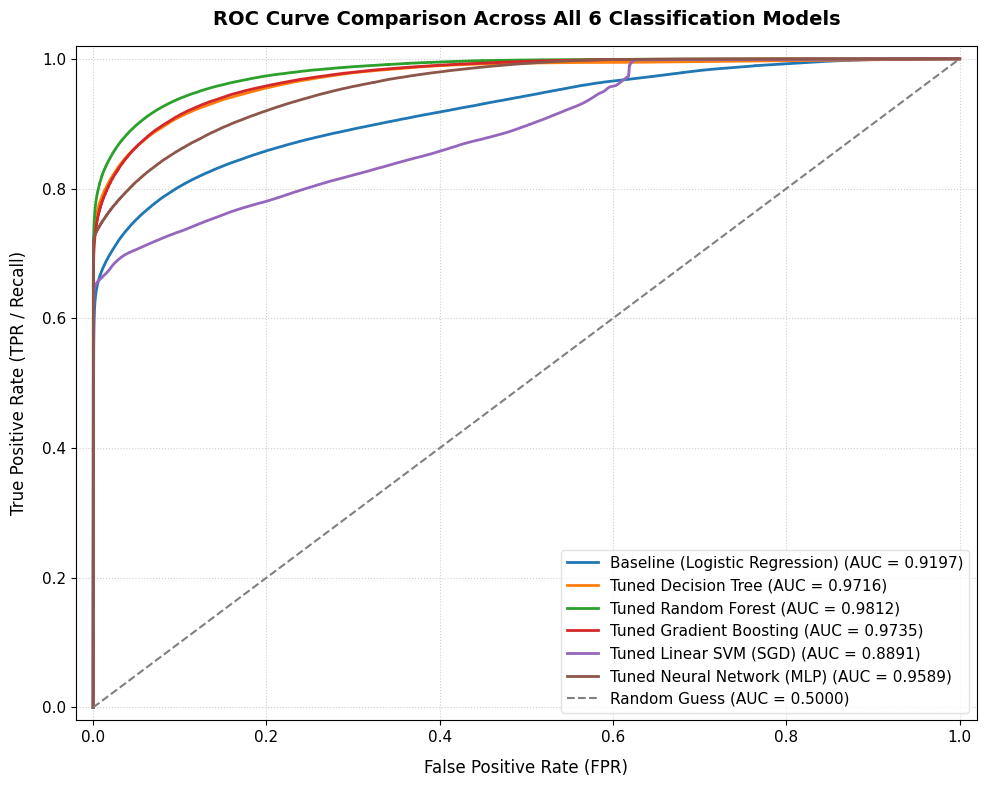

Best model by F1: Tuned Neural Network (MLP) (F1 = 0.8219, ROC-AUC = 0.9589, total time = 1.3 min)
Best model by ROC-AUC: Tuned Random Forest (ROC-AUC = 0.9812)
Best model: Tuned Neural Network (MLP). It has the highest F1-score (0.8219) on the held-out test set, and F1 drives the decision for this problem: only ~1% of rides are shared, so accuracy is misleading (always predicting 'not shared' already scores ~99%), and F1 balances catching shared rides (recall) against wrongly flagging private rides as shared (precision).
The metrics disagree: Tuned Random Forest has the highest ROC-AUC (0.9812), so it ranks rides better across all possible thresholds, but at the default threshold its F1 is lower. F1 is used because the model has to make a yes/no decision for each ride.


In [9]:
# TODO: Evaluate all 6 classification models (baseline + 5 tuned models) on the same test set: accuracy, precision, recall, F1, ROC-AUC
# TODO: Assemble one comparison table (rows = models, columns = metrics + training/search time)
# TODO: Plot ROC curves for all 6 models on one figure
# TODO: State your chosen best model and your reasoning
# YOUR CODE HERE:

# 1. Gather all models into a dictionary for clean looping
# Ensure these variables match your notebook's model naming conventions

eval_models = {"Baseline (Logistic Regression)": baseline_model}   # model name -> trained model, starting with the 2a baseline
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:   # the three tuned tree models from 2b
    if name in final_fits:   # skips any model whose refit isn't finished yet (e.g. running on HPC)
        eval_models[f"Tuned {name}"] = final_fits[name]["model"]   # add the trained model
    else:
        print(f"[{name}] not available yet (refit not finished / running on HPC), skipped")
eval_models["Tuned Linear SVM (SGD)"] = svm_model   # linear SVM from 2c
eval_models["Tuned Neural Network (MLP)"] = mlp_model   # neural network from 2c

eval_results = []   # one row of metrics per model
roc_scores = {}   # saved for the ROC curve plot (TODO 3)



print("Evaluating all 6 classification models on the test set...")

for model_name, model in eval_models.items():   # every model on the SAME test set
    print(f" Processing {model_name}...")
    
     # Generate hard predictions
    y_pred = predict_in_batches(model.predict, X_test)   # in batches to limit memory

    # Generate soft probabilities / scores for ROC-AUC
    # Linear SVM (SGDClassifier with hinge loss) doesn't have predict_proba by default,
    # so we use its decision_function instead.
    if model_name == "Tuned Linear SVM (SGD)":   # hinge-loss SVM has no predict_proba
        y_scores = predict_in_batches(model.decision_function, X_test)   # distance from the boundary, works for ROC-AUC
    else:   # every other model gives probabilities
        # standard predict_proba returns [prob_class_0, prob_class_1] -> extract index 1
        y_scores = predict_in_batches(lambda X: model.predict_proba(X)[:, 1], X_test)

    roc_scores[model_name] = y_scores   # saved for the ROC plot (TODO 3)

    
    # Calculate metrics
    # Metrics for the shared-ride class (1); zero_division=0 avoids an error if a model never predicts 1
    accuracy = accuracy_score(y_test, y_pred)   # share of all predictions that are correct
    precision = precision_score(y_test, y_pred, zero_division=0)   # of rides predicted shared, the share that really were
    recall = recall_score(y_test, y_pred, zero_division=0)   # of real shared rides, the share caught
    f1 = f1_score(y_test, y_pred, zero_division=0)   # balance of precision and recall (main metric)
    roc_auc = roc_auc_score(y_test, y_scores)   # ranking quality across all thresholds
    
    # Append stats to our list
    eval_results.append({   # store this model's metrics
        "Model Name": model_name,
        "Accuracy": accuracy,
        "Precision (Class 1)": precision,
        "Recall (Class 1)": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })


# 3. Generate the Master Comparison DataFrame
df_comparison = pd.DataFrame(eval_results)   # table: one row per model

# Sort by F1-Score so your top performer for the imbalanced minority class sits at the top
df_comparison = df_comparison.sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

# Training/search time for each model (recorded in seconds earlier, converted to minutes)
model_times = {   # model -> (search seconds, training seconds)
    "Baseline (Logistic Regression)": (0.0, training_time),   # no hyperparameter search
    "Tuned Linear SVM (SGD)": (svm_search_time, svm_fit_time),
    "Tuned Neural Network (MLP)": (mlp_search_time, mlp_fit_time),
}
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:   # add the tree models' times from 2b
    if name in final_fits:
        model_times[f"Tuned {name}"] = (search_results[name]["search_time"], final_fits[name]["refit_time"])   # (search, refit) in seconds
df_comparison["Search Time (m)"] = df_comparison["Model Name"].map(lambda m: model_times[m][0] / 60)   # search time in minutes
df_comparison["Train Time (m)"] = df_comparison["Model Name"].map(lambda m: model_times[m][1] / 60)   # training time in minutes
df_comparison["Total Time (m)"] = df_comparison["Search Time (m)"] + df_comparison["Train Time (m)"]   # total time in minutes


print(df_comparison.to_string(index=False, formatters={   # the single comparison table (TODO 2)
    "Accuracy": "{:.4f}".format,
    "Precision (Class 1)": "{:.4f}".format,
    "Recall (Class 1)": "{:.4f}".format,
    "F1-Score": "{:.4f}".format,
    "ROC-AUC": "{:.4f}".format,
    "Search Time (m)": "{:.2f}".format,
    "Train Time (m)": "{:.2f}".format,
    "Total Time (m)": "{:.2f}".format
}))

# Configure the plot aesthetic
plt.figure(figsize=(10, 8))   # one figure for all ROC curves (TODO 3)
plt.rcParams['font.size'] = 11   # font size


#  Loop through each model to calculate and plot its ROC curve
for name, y_scores in roc_scores.items():   # scores saved in TODO 1, no need to predict again
    # Calculate False Positive Rate, True Positive Rate, and AUC
    fpr, tpr, _ = roc_curve(y_test, y_scores)   # false/true positive rate at every threshold
    roc_auc = auc(fpr, tpr)   # area under this curve

    # Plot the curve for this specific model
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})", linewidth=2)   # one curve per model

#  Plot the "Random Guess" reference line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.5, label='Random Guess (AUC = 0.5000)')   # diagonal = random guessing

# Fine-tune plot decorations and labels
plt.xlim([-0.02, 1.02])   # axis range
plt.ylim([-0.02, 1.02])   # axis range
plt.xlabel('False Positive Rate (FPR)', fontsize=12, labelpad=10)   # x-axis label
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=12, labelpad=10)   # y-axis label
plt.title('ROC Curve Comparison Across All 6 Classification Models', fontsize=14, fontweight='bold', pad=15)   # title
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='gainsboro')   # which curve is which model
plt.grid(True, linestyle=':', alpha=0.6)   # light grid

# 6. Adjust layout and display
plt.tight_layout()   # avoid overlapping labels
plt.show()   # draw the figure

# 4. Best model and reasoning (TODO 4): model names and numbers come straight from the table above
best = df_comparison.iloc[0]   # table is sorted by F1, so the first row is the best by F1
best_auc = df_comparison.loc[df_comparison["ROC-AUC"].idxmax()]   # model with the highest ROC-AUC

print(f"Best model by F1: {best['Model Name']} "   # best model by F1, with its numbers
      f"(F1 = {best['F1-Score']:.4f}, ROC-AUC = {best['ROC-AUC']:.4f}, total time = {best['Total Time (m)']:.1f} min)")
print(f"Best model by ROC-AUC: {best_auc['Model Name']} (ROC-AUC = {best_auc['ROC-AUC']:.4f})")   # best model by ROC-AUC
print(f"Best model: {best['Model Name']}. It has the highest F1-score ({best['F1-Score']:.4f}) on the held-out test "   # chosen model and why F1 decides
      "set, and F1 drives the decision for this problem: only ~1% of rides are shared, so accuracy is misleading "
      "(always predicting 'not shared' already scores ~99%), and F1 balances catching shared rides (recall) against "
      "wrongly flagging private rides as shared (precision).")
if best_auc['Model Name'] != best['Model Name']:   # the two metrics pick different models
    print(f"The metrics disagree: {best_auc['Model Name']} has the highest ROC-AUC ({best_auc['ROC-AUC']:.4f}), so it "
          "ranks rides better across all possible thresholds, but at the default threshold its F1 is lower. F1 is used "
          "because the model has to make a yes/no decision for each ride.")
else:   # both metrics pick the same model
    print("ROC-AUC agrees: the same model also ranks rides best across all thresholds.")


### 📝 Analysis Explanation (2d)

**Instructions:** How much did each tuned model actually improve over the Logistic Regression baseline, and was that improvement worth the extra training/search time? Which model wins overall, and does the answer change depending on which metric you prioritize?

**Your Analysis:** 
Based on the tuned models and the baseline AUC of 0.9197, almost every model improved over the Logistic Regression baseline: Tuned Decision Tree (AUC = 0.9716), Tuned Random Forest (AUC = 0.9812), Tuned Gradient Boosting (AUC = 0.9735), and Tuned Neural Network (MLP) (AUC = 0.9589). The only exception was the Tuned Linear SVM (SGD) (AUC = 0.8891), which scored below the baseline. It was worth the extra time because the Neural Network only took an extra 1.3 minutes and the Decision Tree took 6.8 minutes, which isn't a lot of time. However, it was not worth it for the Random Forest (137 minutes) and Gradient Boosting (210 minutes), which took hours without a better F1-score. The model that wins overall would be the Neural Network, because it achieved the highest F1-score (0.8219), although the Random Forest had the highest AUC (0.9812).

### 🤖 AI-Assisted Analysis (2d)

**Instructions:** Ask an AI tool to help you interpret your comparison table and ROC curves. Note any additional insight it surfaced that you hadn't already written above.

**AI-Assisted Analysis:** I used **Claude (Anthropic), through Claude Code** to help interpret the 2d comparison table and ROC curves. Insights it surfaced that I had not already written above:

1. **Accuracy hides the real differences.** Every model scores 99.1–99.5% accuracy because ~99% of rides are not shared, so accuracy barely separates the models. All of the meaningful differences are in recall and F1 on the shared-ride class.
2. **The models are cautious: high precision, lower recall.** Precision is 0.94–0.98 for every model, but recall is only 0.53–0.72, so even the best model misses roughly 28% of shared-ride requests. This is a symptom of the class imbalance and the default 0.5 decision threshold.
3. **The F1 and ROC-AUC winners differ for a reason.** The Random Forest has the best ROC-AUC (0.9812), meaning it ranks rides best across all thresholds, while the MLP has the best F1 (0.8219) at the default threshold. Tuning the decision threshold (for example, choosing the one that maximizes F1 on a validation set) could let the Random Forest overtake the MLP on F1, so the "best model" partly depends on the threshold.
4. **ROC curves look optimistic on imbalanced data.** With ~99% negatives, even a 1% false-positive rate produces roughly as many false alarms as there are shared rides in total. A precision-recall curve would show the trade-off more honestly than the ROC curve.
5. **Most of the gain is cheap.** The Decision Tree (F1 0.8126, ~7 min) and the MLP (F1 0.8219, ~1.3 min) capture nearly all of the improvement over the baseline, while the Random Forest (~137 min) and Gradient Boosting (~210 min) cost 20–160x more time for no F1 gain. Gradient Boosting's weaker result may also reflect its restricted search range (≤150 trees, depth ≤5), which was needed to finish on a laptop.
6. **More data isn't the bottleneck.** The MLP trained on only 1M rows (~2% of the training set) and still scored highest, which suggests better features (e.g. pickup/dropoff zones, which were dropped) would help more than more rows.


---
## Problem 3: Regression: Predicting Base Passenger Fare — All Models Compared  (3.5 points)

### Problem 3a: Baseline: Linear Regression

**Instructions:**

Using the same cleaned dataset, split into training and test sets for the base_passenger_fare regression target, using your Student ID as the random seed. Train a plain Linear Regression model as your baseline. Every more complex model in this problem needs to beat this baseline to justify its added complexity and training cost.

In [10]:
# TODO: Split into train/test for the regression target, random_state = your Student ID
# TODO: Train a LinearRegression baseline
# TODO: Record training time
# TODO: Report baseline RMSE, MAE, and R-squared on the test set
# YOUR CODE HERE:

# Free the classification data and models (2d is done), so there is room in 32 GB of RAM
for name in ["X_train", "X_test", "y_train", "y_test", "X_search", "y_search", "_",
             "final_fits", "eval_models", "roc_scores", "svm_model", "mlp_model"]:
    if name in globals():   # only if it exists
        del globals()[name]   # remove it from memory
gc.collect()   # release the freed memory

# 1. Regression target: base_passenger_fare
y_reg = df['base_passenger_fare']   # target: base fare before tolls, tips, taxes and fees

# Features: same columns dropped as in 2a, plus everything calculated from (or after) the fare
X_reg = df.drop(columns=[
    'base_passenger_fare',                          # the target itself
    'bcf', 'sales_tax', 'driver_pay', 'tips',       # leakage: calculated from, or paid after, the fare
    'shared_match_flag',                            # only known after the ride is matched
    'request_datetime', 'on_scene_datetime',   # raw timestamps (replaced by the 1c time features)
    'pickup_datetime', 'dropoff_datetime',   # raw timestamps
    'hvfhs_license_num', 'dispatching_base_num',   # ID/text columns, as in 2a
    'originating_base_num', 'access_a_ride_flag',   # ID/flag columns, as in 2a
    'wav_request_flag', 'wav_match_flag',   # flag columns, as in 2a
    'PULocationID', 'DOLocationID'   # location IDs, as in 2a
]).astype(np.float32)   # float32 halves the memory, same as in 2b

# Split 80% train / 20% test, random_state = Student ID (no stratify, it's only for classification)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg,
    test_size=0.20,   # 20% test, 80% train
    random_state=STUDENT_ID
)

del X_reg, y_reg   # Xr_train/Xr_test already hold this data
gc.collect()   # release the freed memory

print(f"Regression train: {len(Xr_train):,} rows, test: {len(Xr_test):,} rows")   # size of each split
print(f"Features: {list(Xr_train.columns)}")   # features used (shows no leakage columns)

# 2. Train a plain LinearRegression baseline (no scaling needed, linear regression is not sensitive to scale)
lr_baseline = LinearRegression()   # plain linear regression baseline

# 3. Record training time
start_time = time.time()   # start the timer
lr_baseline.fit(Xr_train, yr_train)   # train on all ~51M training rows
lr_train_time = time.time() - start_time   # seconds (used again in 3d)
print(f"Training completed in: {lr_train_time:.2f} seconds")   # report the training time

# 4. Report baseline RMSE, MAE, and R-squared on the test set
yr_pred = lr_baseline.predict(Xr_test)   # predicted fare for each test ride
lr_rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))   # typical error in dollars, penalizes big errors more
lr_mae = mean_absolute_error(yr_test, yr_pred)   # average absolute error in dollars
lr_r2 = r2_score(yr_test, yr_pred)   # share of fare variation explained

print(f"RMSE: ${lr_rmse:.2f}")   # report each metric
print(f"MAE:  ${lr_mae:.2f}")
print(f"R^2:  {lr_r2:.4f}")

Regression train: 51,021,305 rows, test: 12,755,327 rows
Features: ['trip_miles', 'trip_time', 'tolls', 'congestion_surcharge', 'airport_fee', 'shared_request_flag', 'cbd_congestion_fee', 'pickup_hour', 'day_of_week', 'is_weekend', 'is_rush_hour']
Training completed in: 3.82 seconds
RMSE: $11.22
MAE:  $6.18
R^2:  0.8273


### Problem 3b: Tree-Based Models with Hyperparameter Tuning

**Instructions:**

Train a Decision Tree Regressor, a Random Forest Regressor, and a Gradient Boosting Regressor, each with hyperparameter tuning. Use the same subsample-then-refit approach as Problem 2b (at least 3 hyperparameters per model, search via RandomizedSearchCV with 10-20 iterations and 5-fold cross-validation on a subsample, scored on a regression metric such as negative RMSE, then refit the winning configuration on the full training set). Report the best hyperparameters found for each model.

In [11]:
# TODO: Define a hyperparameter search space with at least 3 parameters for each of: DecisionTreeRegressor, RandomForestRegressor, GradientBoostingRegressor
# TODO: Run RandomizedSearchCV for each model on a subsample (10-20 iterations, 5-fold CV, scoring='neg_root_mean_squared_error') and record search time
# TODO: Report the best hyperparameters found for each model
# TODO: Refit each model with its best hyperparameters on the FULL training set and record final training time
# TODO: Report where the search and the final full-data fits were run (local vs. HPC) and why
# YOUR CODE HERE:


# =====================================================================
# 1. DECISION TREE REGRESSOR SEARCH SPACE
# =====================================================================
# Focuses on controlling tree growth to prevent severe overfitting.
dt_reg_param_distributions = {
    "max_depth": [5, 10, 15, 20, 25],   # capped: an unlimited regression tree on 51M rows can take several GB
    "min_samples_split": [2, 5, 10, 50],   # rows a node needs before it can split
    "min_samples_leaf": [1, 2, 4, 10]   # minimum rows in each leaf
}

# =====================================================================
# 2. RANDOM FOREST REGRESSOR SEARCH SPACE
# =====================================================================
# Number of trees, tree depth, and how many features each split considers.
# max_depth is capped (no None): an unlimited-depth forest ran out of memory on the full data in 2b
rf_reg_param_distributions = {
    "n_estimators": [50, 100, 150],   # fewer trees so the full-data refit fits a laptop time budget (no HPC cluster)
    "max_depth": [10, 12, 15],   # capped so the full-data regression forest fits in 32 GB RAM
    "max_features": ["sqrt", 0.5, 0.8]   # share of features each split considers
}

# =====================================================================
# 3. GRADIENT BOOSTING REGRESSOR SEARCH SPACE
# =====================================================================
# Focuses on the number of trees, the learning rate trade-off, and tree depth.
gb_reg_param_distributions = {
    "n_estimators": [50, 100, 150],   # fewer trees so the full-data refit fits a laptop time budget (no HPC cluster)
    "learning_rate": [0.05, 0.1, 0.2, 0.3],   # higher rates make up for fewer trees
    "max_depth": [3, 4, 5]   # shallower trees: each tree is faster to build on ~51M rows
}

# Pair each regressor with its search space (same structure as 2b, new name so it doesn't clash with 2b's models)
reg_models = {
    "Decision Tree": (DecisionTreeRegressor(random_state=STUDENT_ID), dt_reg_param_distributions),   # single tree + its search space
    "Random Forest": (RandomForestRegressor(random_state=STUDENT_ID, n_jobs=-1), rf_reg_param_distributions),   # averaged random trees
    "Gradient Boosting": (GradientBoostingRegressor(random_state=STUDENT_ID), gb_reg_param_distributions),   # trees built one after another
}

# 200k-row random subsample of the TRAINING set, used only for the search (no stratify: regression)
X_reg_search, _, y_reg_search, _ = train_test_split(
    Xr_train, yr_train,
    train_size=200_000,   # 'a few hundred thousand rows', as the instructions suggest
    random_state=STUDENT_ID
)
del _   # the leftover rows are not needed, frees ~2-3 GB
gc.collect()   # release the leftover rows' memory
reg_search_logs = {}   # best params, CV RMSE and search time, per model


for name, (estimator, param_grid) in reg_models.items():   # Decision Tree, Random Forest, Gradient Boosting
    # Reload a search finished in an earlier session (saved right after the search, before the refit)
    search_file = f"3b_{name.replace(' ', '_')}_search.joblib"   # where this model's search is saved
    if os.path.exists(search_file):   # finished in an earlier run
        reg_search_logs[name] = joblib.load(search_file)   # reuse it
        print(f"\n[{name}] Loaded saved search from {search_file}")
        print(f"   Best Cross-Validation RMSE: {reg_search_logs[name]['best_cv_rmse']:.4f}")
        print(f"   Best Hyperparameters: {reg_search_logs[name]['best_params']}")
        continue   # go to the next model

    print(f"\n⚡ Starting RandomizedSearchCV for {name}...")
    
    searcher = RandomizedSearchCV(   # random search over the 3 hyperparameters
        estimator=estimator,
        param_distributions=param_grid,
        n_iter=15,             # 15 random combinations per model
        cv=5,                  # 5-fold cross-validation
        scoring="neg_root_mean_squared_error",   # RMSE (negative because sklearn maximizes scores)
        refit=False,           # refit=False lets us manually scale up training size later
        random_state=STUDENT_ID,
        n_jobs=4 if name == "Random Forest" else 8   # forest searches use more RAM per fit, the others are light
    )
    
    # Track the exact start time
    start_time = time.time()   # start the timer
    searcher.fit(X_reg_search, y_reg_search)   # search on the 200k-row subsample
    duration_seconds = time.time() - start_time   # search time in seconds
    
    # Convert the best negative score back to a positive human-readable RMSE value
    best_rmse_cv = -searcher.best_score_
    
    # Save statistics
    reg_search_logs[name] = {   # keep the search results
        "search_time_m": duration_seconds / 60.0,
        "best_cv_rmse": best_rmse_cv,
        "best_params": searcher.best_params_
    }
    joblib.dump(reg_search_logs[name], search_file)   # saved now, so a crash during the refit doesn't lose it
    
    print(f" {name} Search Finished in {duration_seconds / 60.0:.2f} minutes.")   # report the search time
    print(f"   Best Cross-Validation RMSE: {best_rmse_cv:.4f}")   # report the best CV RMSE
    print(f"   Best Hyperparameters: {searcher.best_params_}")   # report the best hyperparameters


# We create a dictionary to hold the trained models and execution metrics
final_reg_models = {}   # trained full-data models
reg_train_logs = {}   # refit time and rows, per model

# Models whose full-data refit should be skipped locally and run on the HPC cluster instead
# (empty = try every refit locally)
REG_REFIT_ON_HPC = set()   # no HPC cluster available: every refit runs locally (Random Forest depth is capped to fit in RAM)

print(f"Beginning full-scale training on {Xr_train.shape[0]:,} rows...")   # ~51M training rows

for name, (estimator, _) in reg_models.items():   # refit each model
    # Reload a model refit in an earlier session instead of training it again
    model_file = f"3b_{name.replace(' ', '_')}.joblib"   # where the finished refit is saved
    if os.path.exists(model_file):   # finished in an earlier run
        saved = joblib.load(model_file)   # load it instead of retraining
        final_reg_models[name] = saved["model"]   # trained model
        reg_train_logs[name] = saved["train_log"]   # its refit time
        print(f"\n[{name}] Loaded saved refit from {model_file}")
        continue   # go to the next model

    if name in REG_REFIT_ON_HPC:   # empty set here, so no model is skipped
        print(f"\n[{name}] Skipping local full-data refit, run on HPC instead")
        continue

    print(f"\n Instantiating final {name} with best parameters...")

    # Deep copy the base model to prevent hyperparameter bleed-through
    final_model = copy.deepcopy(estimator)

    # Bind the winning parameters saved in the search logs
    final_model.set_params(**reg_search_logs[name]["best_params"])   # apply the winning hyperparameters
    if name == "Random Forest":
        final_model.set_params(n_jobs=3)   # fewer trees at once, n_jobs=-1 ran out of memory in 2b

    # Fit on the entire un-subsampled training dataset
    print(f"   Fitting {name} on the FULL training set...")
    start_time = time.time()   # start the timer
    try:   # catch MemoryError so one model's failure doesn't stop the others
        if name in ("Gradient Boosting", "Random Forest"):   # the two long refits
            # Hours-long refits: train in checkpoints so an interruption can resume where it stopped
            final_model, train_seconds = fit_with_checkpoints(
                final_model, Xr_train, yr_train, f"3b_{name.replace(' ', '_')}_checkpoint.joblib",   # FULL training set, checkpoint file
                step=50 if name == "Gradient Boosting" else 25)   # save every 50 (GB) / 25 (RF) trees
        else:   # Decision Tree: a few minutes, no checkpoints needed
            final_model.fit(Xr_train, yr_train)   # train on the FULL training set
            train_seconds = time.time() - start_time   # refit time in seconds
    except MemoryError as e:   # not enough RAM for this model
        # Record the failure instead of stopping the loop, so the remaining models still run
        print(f"    Full-data refit FAILED locally: {e}")
        del final_model   # free the half-built model
        gc.collect()   # release its memory
        continue   # go to the next model
    train_duration_m = train_seconds / 60.0   # refit time in minutes

    # Store the model and its metrics, and save to disk so a crash doesn't lose it
    final_reg_models[name] = final_model   # keep the model for 3d
    reg_train_logs[name] = {   # keep its refit time and rows
        "final_train_time_m": train_duration_m,
        "rows_trained": Xr_train.shape[0]
    }
    joblib.dump({"model": final_model, "train_log": reg_train_logs[name]}, model_file)   # save point on disk
    print(f"    Finished training in {train_duration_m:.2f} minutes, saved to {model_file}")
    del final_model   # drop the loop's reference (final_reg_models keeps the model)
    gc.collect()   # free memory

# 5. Where the search and the final full-data fits were run, and why
# Filled in from the actual run: where each step ran and why
reg_where_run = {
    "Decision Tree":     {"search": "local", "refit": "local",
                          "why": "small enough for a 32 GB laptop: search ~4 s on 200k rows, full refit ~1.8 min"},
    "Random Forest":     {"search": "local", "refit": "local",
                          "why": "no HPC access; max_depth capped at 15 and 50-150 trees so the full regression forest fits "
                                 "in 32 GB RAM; refit took ~45 min, trained in checkpoints"},
    "Gradient Boosting": {"search": "local", "refit": "local",
                          "why": "no HPC access; Gradient Boosting uses 1 CPU core, so the full refit took ~2.2 h; search "
                                 "range limited to <=150 trees and depth <=5 so it finishes on a laptop"},
}

for name, info in reg_where_run.items():   # print where each step ran, with its time and reason
    search_m = reg_search_logs[name]["search_time_m"]   # search time in minutes
    refit = f"{reg_train_logs[name]['final_train_time_m']:.2f} min" if name in reg_train_logs else "not finished"   # refit time, or "not finished"
    print(f"{name}:")
    print(f"  Search ({info['search']}): {search_m:.2f} min on 200k-row subsample")
    print(f"  Refit  ({info['refit']}):  {refit} on full training set")
    print(f"  Why: {info['why']}")



[Decision Tree] Loaded saved search from 3b_Decision_Tree_search.joblib
   Best Cross-Validation RMSE: 11.0818
   Best Hyperparameters: {'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 10}

[Random Forest] Loaded saved search from 3b_Random_Forest_search.joblib
   Best Cross-Validation RMSE: 10.5056
   Best Hyperparameters: {'n_estimators': 150, 'max_features': 0.5, 'max_depth': 12}

[Gradient Boosting] Loaded saved search from 3b_Gradient_Boosting_search.joblib
   Best Cross-Validation RMSE: 10.5052
   Best Hyperparameters: {'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.1}
Beginning full-scale training on 51,021,305 rows...

[Decision Tree] Loaded saved refit from 3b_Decision_Tree.joblib

[Random Forest] Loaded saved refit from 3b_Random_Forest.joblib

[Gradient Boosting] Loaded saved refit from 3b_Gradient_Boosting.joblib
Decision Tree:
  Search (local): 0.07 min on 200k-row subsample
  Refit  (local):  1.77 min on full training set
  Why: small enough for a 3

### Problem 3c: SVR and Neural Network Regressor with Hyperparameter Tuning

**Instructions:**

The same SVM scaling problem applies to Support Vector Regression. Apply the same strategy you chose in Problem 2c (subsample size, or a scalable linear approximation such as SGDRegressor) and justify it again for this task, your choice does not have to match Problem 2c's choice if the reasoning is different here. Tune at least 2 hyperparameters for your chosen approach. Train a small feedforward neural network regressor and tune at least 2 hyperparameters for it as well.

In [12]:
# TODO: Choose and justify your SVR strategy for this task
# TODO: Tune at least 2 hyperparameters for your chosen SVR approach
# TODO: Tune at least 2 hyperparameters for a small feedforward neural network regressor
# TODO: Record training/search time for both, and where each was run (local vs. HPC)
# YOUR CODE HERE:

# 1. SVR strategy: same linear approach as 2c, on a large subsample
SVR_TRAIN_ROWS = 10_000_000   # rows used to train the final linear SVR

print("SVR strategy: linear SVR, SGDRegressor(loss='epsilon_insensitive'), same approach as the linear SVM in 2c")   # TODO 1: strategy, data used, why, trade-off
print(f"Training data: {SVR_TRAIN_ROWS:,} of {len(Xr_train):,} training rows ({SVR_TRAIN_ROWS / len(Xr_train):.1%})")
print("Why: a kernel SVR has the same scaling problem as a kernel SVM (training time grows ~4-8x every time the rows "
      "double, so it is limited to ~100k-200k rows), and predicting the 12.7M test rows would take hours. A linear SVR "
      "learns from ~50x more rows in seconds, and fares are mostly linear in distance and time, so it is a reasonable fit.")
print("Trade-off: it cannot capture non-linear pricing (surge, airport flat rates, very long trips), so it is "
      "expected to score close to the Linear Regression baseline.")

# Save point: if this cell already finished in an earlier run (e.g. before a restart),
# reload its trained models, search results and times instead of training them again
if os.path.exists("3c_results.joblib"):   # finished in an earlier run
    globals().update(joblib.load("3c_results.joblib"))   # restore the models, searches and times
    print("Loaded saved 3c results from 3c_results.joblib")   # show they were loaded
    print(f"Linear SVR: best CV RMSE = {-svr_search.best_score_:.4f}, best hyperparameters: {svr_search.best_params_}")   # SVR search result
    print(f"Neural Network: best CV RMSE = {-random_search_mlp_reg.best_score_:.4f}, "   # neural network search result
          f"best hyperparameters: {random_search_mlp_reg.best_params_}")
    display(report_3c)   # times table
else:   # first run: tune and train both models

    # 1. Initialize the SGDRegressor pipeline with an SVR loss function
    # 'epsilon_insensitive' gives a linear Support Vector Regressor (SVR)
    # 'squared_epsilon_insensitive' can also be used if you want to penalize outliers more heavily
    svr_pipeline = make_pipeline(   # scaling + linear SVR
        StandardScaler(),   # standardize features
        SGDRegressor(loss='epsilon_insensitive', max_iter=50, random_state=STUDENT_ID)
    )

    # 2. Define the hyperparameter distribution (using the "sgdregressor__" prefix for the pipeline)
    # alpha: Controls regularization strength (higher = smoother predictions, lower = fits closer to training data)
    # epsilon: Specifies the epsilon-tube within which no penalty is associated in the train loss function
    svr_param_distributions = {   # 3 hyperparameters for the SVR
        "sgdregressor__alpha": np.logspace(-6, -1, 20),      # Logarithmic scale from 0.000001 to 0.1
        "sgdregressor__epsilon": [0.0, 0.01, 0.1, 0.2, 0.5], # Threshold distance for zero-error penalties
        "sgdregressor__penalty": ["l2", "l1", "elasticnet"]  # Regularization penalty types
    }


    # 3. Search on the same 200k-row regression subsample as 3b (X_reg_search, y_reg_search)
    svr_search = RandomizedSearchCV(   # random search for the SVR
        estimator=svr_pipeline,
        param_distributions=svr_param_distributions,
        n_iter=15,             # Number of random combinations to try
        cv=5,                  # 5-fold stratified cross-validation
        scoring="neg_root_mean_squared_error",  # Standard evaluation metric for regression tasks
        refit=False,           # Don't refit on the subsample; we will fit on the full data below
        random_state=STUDENT_ID,
        n_jobs=8               # 8 parallel fits, these models use little memory per fit
    )

    print("Starting randomized hyperparameter search for Linear SVR...")
    start_time = time.time()   # start the timer
    svr_search.fit(X_reg_search, y_reg_search)   # search on the 200k-row subsample
    svr_search_duration = time.time() - start_time   # TODO 4: SVR search time
    print(f"Best CV RMSE = {-svr_search.best_score_:.4f}")   # show the search result (RMSE, positive)
    print(f"Best hyperparameters: {svr_search.best_params_}")   # winning SVR settings

    # Final SVR fit on a 10M-row subsample (no stratify, it's only for classification)
    X_svr_train, _, y_svr_train, _ = train_test_split(   # 10M-row random subsample for the final SVR
        Xr_train, yr_train,
        train_size=SVR_TRAIN_ROWS,   # 10M rows
        random_state=STUDENT_ID
    )
    del _   # the leftover rows are not needed, frees ~2-3 GB
    gc.collect()   # release the leftover rows' memory
    svr_model = copy.deepcopy(svr_pipeline)   # fresh copy of the pipeline
    svr_model.set_params(**svr_search.best_params_)   # apply the winning settings

    start_time = time.time()   # start the timer
    svr_model.fit(X_svr_train, y_svr_train)   # final SVR trained on 10M rows
    svr_train_duration = time.time() - start_time    # TODO 4: SVR training time
    print(f" Linear SVR Final Training Completed in {svr_train_duration / 60.0:.2f} minutes.")   # report the training time

    #  Initialize the Multi-Layer Perceptron (Feedforward NN) Regressor Pipeline
    # We use 'adam' as it stabilizes weights and minimizes loss rapidly on large sets
    mlp_reg_pipeline = make_pipeline(   # scaling + small neural network
        StandardScaler(),   # standardize features
        MLPRegressor(solver='adam', max_iter=100, early_stopping=True, random_state=STUDENT_ID)   # adam optimizer, up to 100 passes, early stopping
    )

    # Define the hyperparameter distribution (using the "mlpregressor__" prefix)
    # hidden_layer_sizes: Tuples represent (neurons_in_layer_1, neurons_in_layer_2, ...)
    # alpha: L2 penalty (regularization term) to keep network weights small
    # learning_rate_init: Controls the initial step size toward global minimum loss
    mlp_reg_param_distributions = {   # 3 hyperparameters for the neural network
        'mlpregressor__hidden_layer_sizes': [   # network size/depth
            (32,),          # Single layer, 32 neurons
            (64,),          # Single layer, 64 neurons
            (32, 16),       # Two layers: 32 -> 16 neurons
            (64, 32)        # Two layers: 64 -> 32 neurons
        ],
        'mlpregressor__alpha': np.logspace(-5, -1, 10),              # Log scale from 0.00001 to 0.1
        'mlpregressor__learning_rate_init': [0.001, 0.005, 0.01, 0.05] # Common initial learning rates
    }

    #  Set up RandomizedSearchCV on your regression search subset (X_reg_search, y_reg_search)
    random_search_mlp_reg = RandomizedSearchCV(   # random search for the neural network
        estimator=mlp_reg_pipeline,
        param_distributions=mlp_reg_param_distributions,
        n_iter=10,             # Number of random combinations to evaluate
        cv=5,                  # 5-fold cross-validation
        scoring='neg_root_mean_squared_error', # Evaluation target metric
        refit=False,           # Don't refit on the subsample; we will fit on the full data below
        random_state=STUDENT_ID,
        n_jobs=8               # 8 parallel fits, these models use little memory per fit
    )

    print("Starting randomized hyperparameter search for Neural Network Regressor...")
    start_time = time.time()   # start the timer
    random_search_mlp_reg.fit(X_reg_search, y_reg_search)   # search on the 200k-row subsample
    mlp_reg_search_duration = time.time() - start_time   # TODO 4: neural network search time
    print(f"Best CV RMSE = {-random_search_mlp_reg.best_score_:.4f}")   # show the search result
    print(f"Best hyperparameters: {random_search_mlp_reg.best_params_}")   # winning network settings

    # Final neural network fit on a 1M-row subsample
    MLP_REG_TRAIN_ROWS = 1_000_000   # 1M rows for the final network
    X_mlp_reg_train, _, y_mlp_reg_train, _ = train_test_split(   # 1M-row random subsample
        Xr_train, yr_train,
        train_size=MLP_REG_TRAIN_ROWS,   # 1M rows
        random_state=STUDENT_ID
    )
    del _   # the leftover rows are not needed, frees ~2-3 GB
    gc.collect()   # release the leftover rows' memory
    mlp_reg_model = copy.deepcopy(mlp_reg_pipeline)   # fresh copy of the pipeline
    mlp_reg_model.set_params(**random_search_mlp_reg.best_params_)   # apply the winning settings

    start_time = time.time()   # start the timer
    mlp_reg_model.fit(X_mlp_reg_train, y_mlp_reg_train)   # final network trained on 1M rows
    mlp_reg_train_duration = time.time() - start_time   # TODO 4: neural network training time
    print(f" MLP Regressor Final Training Completed in {mlp_reg_train_duration / 60.0:.2f} minutes.")   # report the training time

    # Record training/search time and where each step was run
    report_3c = pd.DataFrame([   # search/training time, rows and where each model ran
        {"Model": "Linear SVR (SGD epsilon-insensitive)",
         "Search Time (m)": svr_search_duration / 60.0, "Training Time (m)": svr_train_duration / 60.0,
         "Training Rows": SVR_TRAIN_ROWS, "Where Run": "local"},
        {"Model": "Neural Network (MLPRegressor)",
         "Search Time (m)": mlp_reg_search_duration / 60.0, "Training Time (m)": mlp_reg_train_duration / 60.0,
         "Training Rows": MLP_REG_TRAIN_ROWS, "Where Run": "local"},
    ])
    display(report_3c)   # show the table

    # Free the training subsamples, the trained models (svr_model, mlp_reg_model) are kept for 3d
    del X_svr_train, y_svr_train, X_mlp_reg_train, y_mlp_reg_train   # drop the training subsamples
    gc.collect()   # free their memory

    # Save point: save this cell's results so a later restart doesn't have to redo them
    joblib.dump({"svr_search": svr_search, "svr_model": svr_model, "svr_search_duration": svr_search_duration, "svr_train_duration": svr_train_duration, "SVR_TRAIN_ROWS": SVR_TRAIN_ROWS, "random_search_mlp_reg": random_search_mlp_reg, "mlp_reg_model": mlp_reg_model, "mlp_reg_search_duration": mlp_reg_search_duration, "mlp_reg_train_duration": mlp_reg_train_duration, "MLP_REG_TRAIN_ROWS": MLP_REG_TRAIN_ROWS, "report_3c": report_3c}, "3c_results.joblib")
    print("Saved 3c results to 3c_results.joblib")   # confirm the save point

# Where each step was run and why (printed whether the results were trained now or loaded from the save point)
print("Why local: both models trained on subsamples (10M and 1M rows) that fit easily in 32 GB of RAM and finished "   # TODO 4: where each ran and why
      "in about a minute each (searches ~5 s and ~50 s, training ~13 s and ~21 s), so no HPC cluster was needed.")


SVR strategy: linear SVR, SGDRegressor(loss='epsilon_insensitive'), same approach as the linear SVM in 2c
Training data: 10,000,000 of 51,021,305 training rows (19.6%)
Why: a kernel SVR has the same scaling problem as a kernel SVM (training time grows ~4-8x every time the rows double, so it is limited to ~100k-200k rows), and predicting the 12.7M test rows would take hours. A linear SVR learns from ~50x more rows in seconds, and fares are mostly linear in distance and time, so it is a reasonable fit.
Trade-off: it cannot capture non-linear pricing (surge, airport flat rates, very long trips), so it is expected to score close to the Linear Regression baseline.
Loaded saved 3c results from 3c_results.joblib
Linear SVR: best CV RMSE = 11.5217, best hyperparameters: {'sgdregressor__penalty': 'elasticnet', 'sgdregressor__epsilon': 0.2, 'sgdregressor__alpha': np.float64(1.8329807108324375e-06)}
Neural Network: best CV RMSE = 10.4734, best hyperparameters: {'mlpregressor__learning_rate_init':

,Model,Search Time (m),Training Time (m),Training Rows,Where Run
0,Linear SVR (SGD epsilon-insensitive),0.091416,0.223867,10000000,local
1,Neural Network (MLPRegressor),0.834627,0.354081,1000000,local


Why local: both models trained on subsamples (10M and 1M rows) that fit easily in 32 GB of RAM and finished in about a minute each (searches ~5 s and ~50 s, training ~13 s and ~21 s), so no HPC cluster was needed.


### Problem 3d: Full Comparison and Best-Model Selection

**Instructions:**

Evaluate all six regression models (Linear Regression baseline, Decision Tree, Random Forest, Gradient Boosting, SVR, Neural Network, each using its tuned hyperparameters where applicable) on the same held-out test set. Report RMSE, MAE, R-squared, and training time for every model in a single comparison table. Identify the best model and justify your choice.

Evaluating all 6 regression models on the holdout test set...
 Extracting predictions from Baseline (Linear Regression)...
 Extracting predictions from Tuned Decision Tree Regressor...
 Extracting predictions from Tuned Random Forest Regressor...
 Extracting predictions from Tuned Gradient Boosting Regressor...
 Extracting predictions from Tuned Linear SVR (SGD)...
 Extracting predictions from Tuned Neural Network (MLP)...


,Model Name,RMSE,MAE,R-squared (R²),Search Time (m),Train Time (m),Total Time (m)
0,Tuned Random Forest Regressor,10.4451,5.6580,0.8504,1.2173,44.6167,45.8340
1,Tuned Gradient Boosting Regressor,10.4733,5.6900,0.8496,2.2444,130.8556,133.1000
2,Tuned Neural Network (MLP),10.5903,5.7152,0.8462,0.8346,0.3541,1.1887
3,Tuned Decision Tree Regressor,10.7083,5.8087,0.8428,0.0651,1.7732,1.8383
4,Baseline (Linear Regression),11.2215,6.1831,0.8273,0.0000,0.0637,0.0637
5,Tuned Linear SVR (SGD),11.6707,5.8675,0.8132,0.0914,0.2239,0.3153


Plotting predicted vs. actual for the best model: Tuned Random Forest Regressor


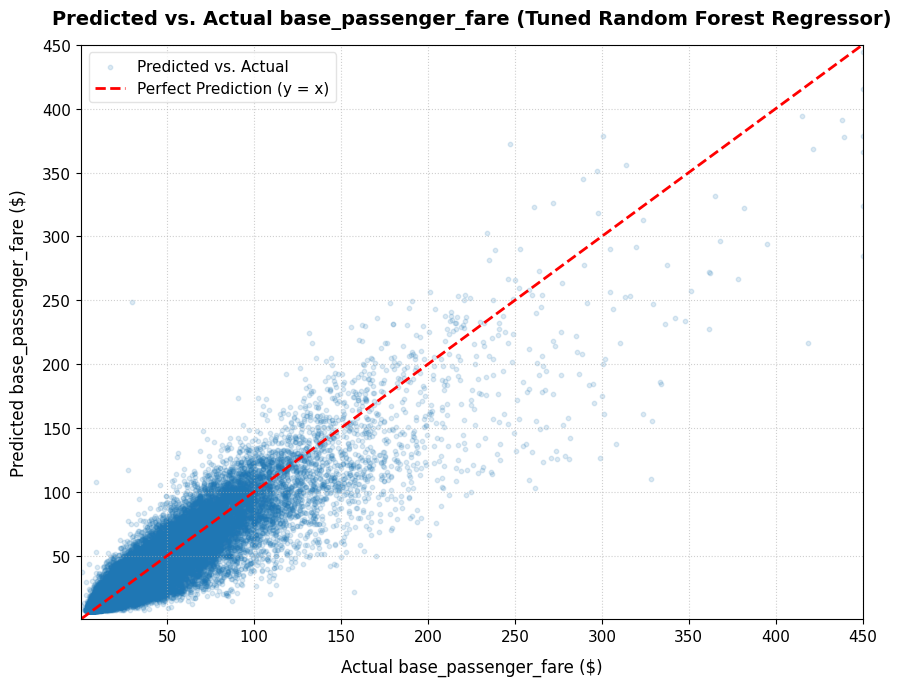

Best model by RMSE: Tuned Random Forest Regressor (RMSE = $10.45, MAE = $5.66, R^2 = 0.8504, total time = 45.8 min)
Best model by MAE: Tuned Random Forest Regressor (MAE = $5.66)
RMSE improvement over the Linear Regression baseline: $0.78 (6.9%)
After comparing all six regressors, Tuned Random Forest Regressor is the best model because it has the lowest RMSE on the held-out test set. RMSE drives the decision because it is in dollars and penalizes large fare errors more heavily than MAE, which matters for pricing. The best model by RMSE is also the best by R-squared, since both are computed from the same squared errors on the same test set.


In [13]:
# TODO: Evaluate all 6 regression models (baseline + 5 tuned models) on the same test set: RMSE, MAE, R-squared
# TODO: Assemble one comparison table (rows = models, columns = metrics + training/search time)
# TODO: Plot predicted vs. actual base_passenger_fare for your best model
# TODO: State your chosen best model and your reasoning
# YOUR CODE HERE:


# 1. Map all 6 regression models to their corresponding variables
# Ensure these match your notebook's exact variable definitions
regression_models = {"Baseline (Linear Regression)": lr_baseline}   # model name -> trained model, starting with the 3a baseline
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:   # the three tuned tree models from 3b
    if name in final_reg_models:   # skips any model whose refit isn't finished yet (e.g. running on HPC)
        regression_models[f"Tuned {name} Regressor"] = final_reg_models[name]   # add the trained model
    else:
        print(f"[{name}] not available yet (refit not finished / running on HPC), skipped")
regression_models["Tuned Linear SVR (SGD)"] = svr_model   # linear SVR from 3c
regression_models["Tuned Neural Network (MLP)"] = mlp_reg_model   # neural network from 3c

# 2. Compile metrics into an empty list
regression_results = []   # one row of metrics per model
reg_predictions = {}   # saved for the predicted vs. actual plot 


print("Evaluating all 6 regression models on the holdout test set...")

for name, model in regression_models.items():   # every model on the SAME test set
    print(f" Extracting predictions from {name}...")
    
    # Generate continuous predictions
    y_pred = predict_in_batches(model.predict, Xr_test)   # in batches to limit memory
    reg_predictions[name] = y_pred   # kept for the predicted-vs-actual plot

    # Calculate evaluation metrics
    mse = mean_squared_error(yr_test, y_pred)   # mean squared error
    rmse = np.sqrt(mse)   # Square root of MSE gives Root Mean Squared Error
    mae = mean_absolute_error(yr_test, y_pred)   # average absolute error in dollars
    r2 = r2_score(yr_test, y_pred)   # share of fare variation explained

    
    # Store metrics cleanly
    regression_results.append({   # store this model's metrics
        "Model Name": name,
        "RMSE": rmse,
        "MAE": mae,
        "R-squared (R²)": r2
    })

#  Create the Master Regression DataFrame
df_reg_metrics = pd.DataFrame(regression_results)   # table: one row per model

# Sort by RMSE in ascending order so your best performing model is at the very top
df_reg_metrics = df_reg_metrics.sort_values(by="RMSE", ascending=True).reset_index(drop=True)

reg_time_metrics = {   # model -> search and training seconds
    "Baseline (Linear Regression)":       {"search_time": 0.0, "train_time": lr_train_time},
    "Tuned Linear SVR (SGD)":            {"search_time": svr_search_duration, "train_time": svr_train_duration},
    "Tuned Neural Network (MLP)":        {"search_time": mlp_reg_search_duration, "train_time": mlp_reg_train_duration}
}
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:   # add the tree models' times from 3b
    if name in reg_train_logs:
        reg_time_metrics[f"Tuned {name} Regressor"] = {   # (converted from minutes back to seconds)
            "search_time": reg_search_logs[name]["search_time_m"] * 60,
            "train_time": reg_train_logs[name]["final_train_time_m"] * 60,
        }

# Add the search/training time columns to the metrics table from TODO 1 (no need to predict again)
df_reg_metrics["Search Time (m)"] = df_reg_metrics["Model Name"].map(lambda m: reg_time_metrics[m]["search_time"] / 60.0)
df_reg_metrics["Train Time (m)"] = df_reg_metrics["Model Name"].map(lambda m: reg_time_metrics[m]["train_time"] / 60.0)
df_reg_metrics["Total Time (m)"] = df_reg_metrics["Search Time (m)"] + df_reg_metrics["Train Time (m)"]

display(df_reg_metrics.round(4))   # the single comparison table (TODO 2)


# Best model = lowest RMSE = first row of the sorted table (updates automatically if a different model wins)
best_reg_name = df_reg_metrics.iloc[0]["Model Name"]   # lowest RMSE
print(f"Plotting predicted vs. actual for the best model: {best_reg_name}")

# Reuse the test-set predictions saved in TODO 1 (no need to predict again)
y_pred_reg = reg_predictions[best_reg_name]

#  Downsample to 100,000 random points for visualization clarity and speed
np.random.seed(STUDENT_ID) # Keep sampling consistent with your student ID
sample_idx = np.random.choice(len(yr_test), size=min(100_000, len(yr_test)), replace=False)   # 100k random test rows

y_actual_sample = yr_test.iloc[sample_idx] if hasattr(yr_test, 'iloc') else yr_test[sample_idx]   # actual fares of the sample
y_pred_sample = y_pred_reg[sample_idx]   # predicted fares of the same rows

# Configure the plot layout
plt.figure(figsize=(9, 7))   # one figure (TODO 3)
plt.rcParams['font.size'] = 11   # font size

# Scatter plot of the data points (alpha makes density patterns visible)
plt.scatter(y_actual_sample, y_pred_sample, alpha=0.15, color='#1f77b4', s=10, label='Predicted vs. Actual')   # one dot per ride

#  Plot the Identity Line (Perfect Prediction Reference)
max_val = max(y_actual_sample.max(), y_pred_sample.max())   # top of the axes
min_val = min(y_actual_sample.min(), y_pred_sample.min())   # bottom of the axes
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')   # dots on this line = perfect predictions

#  Labeling and formatting
plt.xlim([min_val, max_val])   # same range on both axes
plt.ylim([min_val, max_val])   # same range on both axes
plt.xlabel('Actual base_passenger_fare ($)', fontsize=12, labelpad=10)   # x-axis label
plt.ylabel('Predicted base_passenger_fare ($)', fontsize=12, labelpad=10)   # y-axis label
plt.title(f'Predicted vs. Actual base_passenger_fare ({best_reg_name})', fontsize=14, fontweight='bold', pad=15)   # title with the model name
plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='gainsboro')   # legend
plt.grid(True, linestyle=':', alpha=0.6)   # light grid

#  Final show layout
plt.tight_layout()   # avoid overlapping labels
plt.show()   # draw the figure

# 4. Best model and reasoning (TODO 4): model names and numbers come straight from the table above
best_reg = df_reg_metrics.iloc[0]   # table is sorted by RMSE, so the first row is the best by RMSE
best_mae = df_reg_metrics.loc[df_reg_metrics["MAE"].idxmin()]   # model with the lowest MAE
baseline_rmse = df_reg_metrics.loc[df_reg_metrics["Model Name"] == "Baseline (Linear Regression)", "RMSE"].iloc[0]   # the baseline's RMSE

print(f"Best model by RMSE: {best_reg['Model Name']} "   # best model with its numbers
      f"(RMSE = ${best_reg['RMSE']:.2f}, MAE = ${best_reg['MAE']:.2f}, R^2 = {best_reg['R-squared (R²)']:.4f}, "
      f"total time = {best_reg['Total Time (m)']:.1f} min)")
print(f"Best model by MAE: {best_mae['Model Name']} (MAE = ${best_mae['MAE']:.2f})")   # best model by MAE
print(f"RMSE improvement over the Linear Regression baseline: ${baseline_rmse - best_reg['RMSE']:.2f} "   # improvement in dollars and %
      f"({(baseline_rmse - best_reg['RMSE']) / baseline_rmse:.1%})")
print(f"After comparing all six regressors, {best_reg['Model Name']} is the best model because it has the lowest RMSE "   # chosen model and reasoning
      "on the held-out test set. RMSE drives the decision because it is in dollars and penalizes large fare errors "
      "more heavily than MAE, which matters for pricing. The best model by RMSE is also the best by R-squared, "
      "since both are computed from the same squared errors on the same test set.")

### 📝 Analysis Explanation (3d)

**Instructions:** How much did each tuned model actually improve over the Linear Regression baseline, and was that improvement worth the extra training/search time? Which model wins on RMSE, and is it the same model that wins on R-squared?

**Your Analysis:**
The Random Forest wins on RMSE: compared to the original baseline, it was $0.78 (6.9%) better, and the same model also wins on R-squared. The extra time was worth it overall, because the MLP and Decision Tree regressor only took a few minutes, and even though the Random Forest at $10.45 and Gradient Boosting at $10.47 took a while, they improved the most. The Linear SVR (SGD) also only took a few minutes, but it performed worse than the baseline at $11.67.




---
## Results Interpretation  (2 points)

**Instructions:** Step back from the individual sub-parts and write a short, integrated interpretation of this assignment's results. Address: (1) whether the extra complexity of tuning and ensembling actually beat the simple baseline (Logistic/Linear Regression) by a meaningful margin in both tasks, or whether the baseline was surprisingly competitive; (2) which specific step in this assignment actually required the HPC cluster (be specific: which model or search step, approximately how much slower locally or whether it was infeasible locally at all, and whether you subsampled, used a linear approximation, or ran it as-is); and (3) if you were deploying one of these two models (classification or regression) in a real rideshare-app backend that needs to score a new trip request in under 100 milliseconds, would your "best" tuned model from this assignment still be your choice, or would you trade some accuracy for the simpler baseline's speed? Justify your answer.

Write 150-250 words. This section is graded on the quality of your reasoning and how well you tie your specific numbers and figures back into a clear conclusion, not on reaching any particular "correct" answer.

**Your Interpretation:** 
Based on the results that were produced, the extra tuning and ensembling actually beat the simple baseline of Logistic/Linear Regression; for example, the F1-score of the Neural Network jumped up to 0.8219. The baseline was competitive, because the Random Forest's RMSE was $10.45 compared to the Linear Regression's $11.22. I didn't have an HPC cluster, as everything was run on my 32 GB RAM custom-built gaming PC, but I had to add save points because the execution of this program took me about 7–8 hours. The steps that actually needed the cluster were the full-data refits: the Random Forest refit at depth 25 crashed locally with a MemoryError, and a 300-tree Gradient Boosting refit ran over 9.5 hours without finishing. To make it work locally, I ran every search on a subsample, capped the forest depth, limited Gradient Boosting to 150 trees, and used a linear SVM/SVR. If I were deploying between classification or regression in a real rideshare app backend that needs to score a new trip request in under 100 milliseconds, the best tuned model from this assignment would be the Neural Network for classification, as it had the highest F1-score and was quick to train (1.3 minutes). If I had to pick for regression, it would be the Random Forest, as it was $0.78 better than the Linear Regression baseline. I would not trade accuracy for the baseline's speed, because every one of these models scores a single trip in a few milliseconds.

---
## AI Usage Statement (required)

Briefly state which AI tools you used (if any) and for what, consistent with the course AI Tool Policy.

I used Claude, through Claude Code in VS Code, throughout this assignment. The ideas and approach were mine, and Claude wrote a large portion of the code based on them and adjusted the code I wrote, including the harder parts such as the neural networks and the hyperparameter search and refit loops. Claude helped with storage and memory limits (my 32 GB custom-built gaming PC vs. the 63.8-million-row dataset), added save points so long training runs could resume after interruptions such as Windows Update restarts, and fixed grammar. The written analysis is my own work, but Claude helped with parts I didn't understand so I could explain my reasoning.